# Candidate classifier: vessel vs false positive (Nuku'alofa, PlanetScope)

Trains a classifier on the labelled candidates in `ps_labels.gpkg` and evaluates the full chain (detector → classifier) on the held-out test scenes.

1. **Features** per point, sampled in Earth Engine from the same acquisitions and stored background model the detector used (no image downloads)
2. **Random forest** with cross-validation grouped by acquisition (whole scenes held out), PR curve, threshold choice, feature importance, learning curve
3. **Test scenes**: recall and precision of detector alone vs detector + classifier, against your exhaustive test labels
4. *(optional)* Apply to all candidates in all scenes → `vessel_detections.geojson` for heat maps

Run top to bottom. You can re-run it as you label more; it always reads the latest `ps_labels.gpkg` you upload.

## 1. Settings

In [ ]:
GEE_PROJECT = "groupprojectgeog761"
COLLECTION = "planet_nukualofa_wharf"
BG_ASSET = f"projects/{GEE_PROJECT}/assets/bgmodel_{COLLECTION}"
CAND_ASSET = f"projects/{GEE_PROJECT}/assets/candidates_{COLLECTION}"
CAND_GEOJSON = f"/content/drive/MyDrive/planet_exports/candidates_{COLLECTION}.geojson"
OUT_DIR = "/content/drive/MyDrive/tonga-vessels-data/models"

LABELS_FILE = "ps_labels.gpkg"            # your current local labels - uploaded in step 2
ZONE_FILE = "analysis_zone.geojson"

TEST_ACQ = ["20190808_1014", "20211129_2430", "20260607_2575"]
EXCLUDE_ACQ = ["20220118_1026"]           # dropped
TRAIN_ON_MAXAR = False                    # keep Maxar-date scenes out of training (separate evaluation)
INCLUDE_MANUAL_IN_TRAIN = False           # manual points are boats the detector missed; the classifier only ever sees candidates
POSITIVE = {"vessel", "vessel_uncertain", "wake"}

CUTS = {"harbour": 8, "open": 12}         # detector cut-offs used for labelling (baseline)
MATCH_TOL_M = 6.0                         # 2 pixels

# must match the detection notebook
BUFFER_M, KEEP_LIGHT_HAZE = 30, True
EXPORT_THRESH, MAX_BLOB_PX = 6.0, 150

## 2. Setup and inputs

In [ ]:
import re, os, json
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
import ee, geemap
from google.colab import drive, files

drive.mount("/content/drive")
os.makedirs(OUT_DIR, exist_ok=True)
ee.Authenticate()
ee.Initialize(project=GEE_PROJECT)

for f in [LABELS_FILE, ZONE_FILE]:
    if not Path(f).exists():
        print(f"Upload {f}:"); files.upload()

zones = gpd.read_file(ZONE_FILE).to_crs(32701)[["zone", "geometry"]]
lab = gpd.read_file(LABELS_FILE, layer="ps_labels").to_crs(32701)
lab["class"] = lab["class"].fillna("").str.strip()
lab = lab[~lab.acq_id.isin(EXCLUDE_ACQ)].copy()
lab = gpd.sjoin(lab.drop(columns=[c for c in ["zone"] if c in lab]), zones, how="left",
                predicate="within").drop(columns="index_right")
lab["pid"] = np.arange(len(lab))

print(len(lab), "points |", (lab["class"] != "").sum(), "labelled")
print(pd.crosstab(lab.acq_id.isin(TEST_ACQ).map({True: "test", False: "train/eval"}), lab["class"].replace("", "UNLABELLED")))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
819 points | 491 labelled
class       UNLABELLED  false_positive  vessel  vessel_uncertain  wake
acq_id                                                                
test                 0               0      34                 1     4
train/eval         328             315      37                88    12


## 3. Earth Engine: acquisitions, masks and the stored background model
Same definitions as the detection notebook, so features are computed exactly like the detector score.

In [ ]:
col = ee.ImageCollection(f"projects/{GEE_PROJECT}/assets/{COLLECTION}")
SCENE_RE = re.compile(r"^(\d{8})_(\d{6})(?:_\d{1,2})?_([0-9a-f]{4})")
groups = defaultdict(list)
for a in col.aggregate_array("system:index").getInfo():
    m = SCENE_RE.match(a)
    if m:
        groups[f"{m.group(1)}_{m.group(3)}"].append(a)

def build_acq(acq_id, assets):
    proj = col.filter(ee.Filter.eq("system:index", assets[0])).first().select("B1").projection()
    parts = col.filter(ee.Filter.inList("system:index", assets)).map(lambda i: i.updateMask(i.select("B1").gt(0)))
    return parts.mosaic().setDefaultProjection(proj).set("acq_id", acq_id)

def mask_scene(img):
    data = img.select("B1").gt(0).unmask(0)
    not_clear = img.select("Q1").eq(0)
    if KEEP_LIGHT_HAZE:
        not_clear = not_clear.And(img.select("Q4").eq(0))
    bad = (not_clear.Or(img.select("Q3").eq(1)).Or(img.select("Q5").eq(1))
           .Or(img.select("Q6").eq(1))).unmask(0).And(data)
    valid = data.And(bad.focalMax(radius=BUFFER_M, units="meters", kernelType="circle").Not())
    return img.addBands(data.rename("data")).addBands(valid.rename("valid"))

def masked(img):
    return img.select(["B1", "B2", "B3", "B4"]).updateMask(img.select("valid"))

aoi = col.map(lambda i: ee.Feature(i.geometry())).union(10).geometry()
water = ee.ImageCollection("ESA/WorldCover/v200").first().eq(80).unmask(0).clip(aoi)

bm = ee.Image(BG_ASSET)
det_water = bm.select("det_water").selfMask()
bg_ref = bm.select(["bg_VIS", "bg_NIR"], ["VIS", "NIR"])
sigma = bm.select(["sig_VIS", "sig_NIR"], ["VIS", "NIR"])

def _num(d, k):
    return ee.Number(ee.Algorithms.If(d.get(k), d.get(k), 0))

def normalise(img):
    x = (img.select(["B1", "B2", "B3"]).reduce(ee.Reducer.mean()).rename("VIS")
         .addBands(img.select("B4").rename("NIR")).updateMask(det_water))
    med = x.reduceRegion(ee.Reducer.median(), aoi, 9, bestEffort=True, maxPixels=1e8, tileScale=4)
    off = ee.Image.constant([_num(med, "VIS"), _num(med, "NIR")]).rename(["VIS", "NIR"])
    return x.subtract(off).toFloat()

def score_image(t):
    z = t.subtract(bg_ref).divide(sigma)
    zs = z.updateMask(det_water).reduceRegion(ee.Reducer.percentile([25, 50, 75]), aoi, 9,
                                              bestEffort=True, maxPixels=1e8, tileScale=4)
    def p(b, q): return _num(zs, f"{b}_p{q}")
    centre = ee.Image.constant([p("VIS", 50), p("NIR", 50)]).rename(["VIS", "NIR"])
    spread = ee.Image.constant([p("VIS", 75).subtract(p("VIS", 25)).divide(1.349).max(1),
                                p("NIR", 75).subtract(p("NIR", 25)).divide(1.349).max(1)]).rename(["VIS", "NIR"])
    return z.subtract(centre).divide(spread).updateMask(det_water)   # bands VIS, NIR (scaled z)

print(len(groups), "acquisitions; background model bands:", bm.bandNames().getInfo())

27 acquisitions; background model bands: ['det_water', 'bg_VIS', 'bg_NIR', 'sig_VIS', 'sig_NIR']


## 4. Features per point
All computed around the point (candidate centroids can sit a pixel off the brightest pixel):

| feature | meaning |
|---|---|
| `score_pt`, `score_peak` | NIR anomaly score at the point / max within 3×3 px (what the detector thresholds) |
| `zvis_peak` | visible-band anomaly, max within 3×3 px |
| `blob_px` | size of the above-threshold blob |
| `ctx_mean`, `ctx_std`, `n_hot` | score mean / std / number of hot pixels within 30 m (clutter: whitecaps, glint) |
| `c_B1..c_B4` | contrast per band: 3×3 max minus 30 m local median |
| `ndwi_peak` | (G − NIR)/(G + NIR) at the bright pixel (water-like vs object-like) |
| `dist_land`, `dist_cloud` | metres to land / to masked cloud |
| `haze` | UDM2 light haze nearby |
| `is_harbour`, `superdove` | zone, and satellite series (from the satellite ID) |

In [ ]:
FEATS = ["score_pt", "score_peak", "zvis_peak", "blob_px", "ctx_mean", "ctx_std", "n_hot",
         "c_B1", "c_B2", "c_B3", "c_B4", "ndwi_peak", "dist_land", "dist_cloud", "haze"]
K1 = ee.Kernel.square(1)
BIG = 1e4

def feature_image(img):
    m = masked(img)
    sc = score_image(normalise(m))
    score = sc.select("NIR").rename("score_pt")
    hot = score.gt(EXPORT_THRESH)
    blob = hot.selfMask().int().connectedPixelCount(MAX_BLOB_PX, True).unmask(0)
    raw = m.select(["B1", "B2", "B3", "B4"])
    rmax = raw.focalMax(kernel=K1)
    rbg = raw.focalMedian(30, "circle", "meters")
    contrast = rmax.subtract(rbg).rename(["c_B1", "c_B2", "c_B3", "c_B4"])
    ndwi = rmax.normalizedDifference(["B2", "B4"]).rename("ndwi_peak")
    px = ee.Image.pixelArea().sqrt()
    dist_land = water.eq(0).fastDistanceTransform(64).sqrt().multiply(px).unmask(BIG).rename("dist_land")
    invalid = img.select("data").And(img.select("valid").Not()).unmask(0)
    dist_cloud = invalid.fastDistanceTransform(64).sqrt().multiply(px).unmask(BIG).rename("dist_cloud")
    return ee.Image.cat(
        score,
        score.focalMax(kernel=K1).rename("score_peak"),
        sc.select("VIS").focalMax(kernel=K1).rename("zvis_peak"),
        blob.focalMax(kernel=K1).rename("blob_px"),
        score.focalMean(30, "circle", "meters").rename("ctx_mean"),
        score.reduceNeighborhood(ee.Reducer.stdDev(), ee.Kernel.circle(30, "meters")).rename("ctx_std"),
                hot.unmask(0).reduceNeighborhood(ee.Reducer.sum(), ee.Kernel.circle(30, "meters")).rename("n_hot"),
        contrast, ndwi, dist_land, dist_cloud,
        img.select("Q4").unmask(0).focalMax(kernel=K1).rename("haze"),
    ).toFloat()

def sample_features(pts):
    """pts: GeoDataFrame with pid, acq_id, geometry. Returns DataFrame pid + FEATS."""
    out = []
    for i, (a, g) in enumerate(pts.groupby("acq_id")):
        if a not in groups:
            print("  no imagery for", a); continue
        img = mask_scene(build_acq(a, groups[a]))
        fc = geemap.gdf_to_ee(g[["pid", "geometry"]].to_crs(4326))
        res = feature_image(img).reduceRegions(collection=fc, reducer=ee.Reducer.first(),
                                               crs=img.select("B1").projection(), scale=3, tileScale=4)
        df = ee.data.computeFeatures({"expression": res, "fileFormat": "PANDAS_DATAFRAME"})
        out.append(df.drop(columns=[c for c in df.columns if c == "geo"], errors="ignore"))
        print(f"  [{i+1}] {a}: {len(g)} points")
    df = pd.concat(out, ignore_index=True)
    for f in FEATS:
        if f not in df:
            df[f] = np.nan
    return df[["pid"] + FEATS]

def add_meta(df, pts):
    d = df.merge(pts[["pid", "acq_id", "zone"]], on="pid", how="left")
    d["is_harbour"] = (d.zone == "harbour").astype(int)
    d["superdove"] = d.acq_id.str[-4:-2].isin(["24", "25"]).astype(int)
    return d

ALL_FEATS = FEATS + ["is_harbour", "superdove"]

## 5. Training data and features

In [ ]:
sets_ok = {"train", "maxar_eval"} if TRAIN_ON_MAXAR else {"train"}
tr = lab[(lab["class"] != "") & ~lab.acq_id.isin(TEST_ACQ) & lab["set"].isin(sets_ok)]
if not INCLUDE_MANUAL_IN_TRAIN:
    tr = tr[tr.source == "candidate"]
tr = tr.copy()
tr["y"] = tr["class"].isin(POSITIVE).astype(int)
print(f"Training points: {len(tr)} | positives {tr.y.sum()} | negatives {(1 - tr.y).sum()} | scenes {tr.acq_id.nunique()}")
print(tr.groupby("class").size().to_string())

print("Sampling features in Earth Engine...")
F_tr = add_meta(sample_features(tr), tr).merge(tr[["pid", "y", "class"]], on="pid")
F_tr.to_csv(f"{OUT_DIR}/features_train.csv", index=False)
F_tr[ALL_FEATS].describe().T[["count", "mean", "min", "max"]].round(2)

Training points: 420 | positives 113 | negatives 307 | scenes 13
class
false_positive      307
vessel               29
vessel_uncertain     76
wake                  8
Sampling features in Earth Engine...
  [1] 20190821_1069: 42 points
  [2] 20200108_105c: 4 points
  [3] 20200510_106c: 49 points
  [4] 20210421_105a: 63 points
  [5] 20210722_1065: 19 points
  [6] 20210927_2464: 12 points
  [7] 20211222_2403: 26 points
  [8] 20220812_249c: 31 points
  [9] 20221216_2495: 14 points
  [10] 20240518_24f1: 26 points
  [11] 20240520_24c9: 40 points
  [12] 20240602_2424: 47 points
  [13] 20240701_24cf: 47 points


In [ ]:
ALL_FEATS = [f for f in ALL_FEATS if f not in ("dist_land", "is_harbour")]

## 6. Cross-validation grouped by acquisition
Whole scenes are held out in each fold, so the score reflects performance on a scene the model hasn't seen.

5-fold grouped CV | average precision 0.82 (random = 0.27) | ROC AUC 0.91
Best F1 threshold 0.40: precision 0.74, recall 0.76
Recall>=0.90 threshold 0.24: precision 0.54, recall 0.90


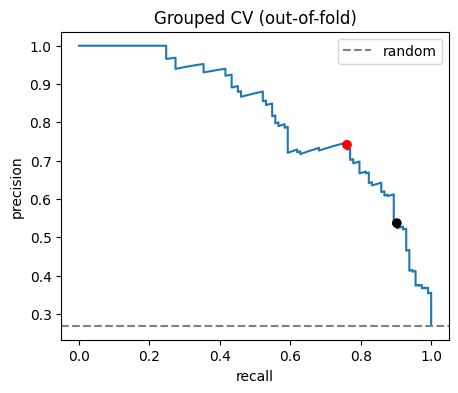

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix)

def make_model():
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                                class_weight="balanced", n_jobs=-1, random_state=0))

X, y, g = F_tr[ALL_FEATS].values, F_tr.y.values, F_tr.acq_id.values
n_splits = min(5, len(np.unique(g)))
cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=0)
oof = cross_val_predict(make_model(), X, y, groups=g, cv=cv, method="predict_proba")[:, 1]

ap, auc = average_precision_score(y, oof), roc_auc_score(y, oof)
base = y.mean()
print(f"{n_splits}-fold grouped CV | average precision {ap:.2f} (random = {base:.2f}) | ROC AUC {auc:.2f}")

prec, rec, thr = precision_recall_curve(y, oof)
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
i_f1 = np.nanargmax(f1[:-1])
i_r90 = np.where(rec[:-1] >= 0.90)[0][-1] if (rec[:-1] >= 0.90).any() else i_f1
THR_F1, THR_R90 = float(thr[i_f1]), float(thr[i_r90])
print(f"Best F1 threshold {THR_F1:.2f}: precision {prec[i_f1]:.2f}, recall {rec[i_f1]:.2f}")
print(f"Recall>=0.90 threshold {THR_R90:.2f}: precision {prec[i_r90]:.2f}, recall {rec[i_r90]:.2f}")

plt.figure(figsize=(5, 4))
plt.plot(rec, prec); plt.axhline(base, ls="--", c="grey", label="random")
plt.scatter([rec[i_f1], rec[i_r90]], [prec[i_f1], prec[i_r90]], c=["r", "k"], zorder=3)
plt.xlabel("recall"); plt.ylabel("precision"); plt.title("Grouped CV (out-of-fold)"); plt.legend(); plt.show()

In [ ]:
THR = THR_F1          # or THR_R90 if missing boats is worse than extra false positives
pred = (oof >= THR).astype(int)
print("Confusion matrix (rows = truth [FP, real], cols = predicted):")
print(confusion_matrix(y, pred))
F_tr["oof"] = oof
print("\nRecall per labelled class at THR:")
print(F_tr[F_tr.y == 1].groupby("class").apply(lambda d: (d.oof >= THR).mean()).round(2).to_string())
print("\nPer scene (out-of-fold):")
print(F_tr.groupby("acq_id").apply(lambda d: pd.Series({
    "n": len(d), "real": d.y.sum(), "kept": (d.oof >= THR).sum(),
    "real_kept": ((d.oof >= THR) & (d.y == 1)).sum()})).astype(int).to_string())

Confusion matrix (rows = truth [FP, real], cols = predicted):
[[277  30]
 [ 27  86]]

Recall per labelled class at THR:
class
vessel              0.69
vessel_uncertain    0.78
wake                0.88

Per scene (out-of-fold):
                n  real  kept  real_kept
acq_id                                  
20190821_1069  42    16    21         15
20200108_105c   4     1     1          1
20200510_106c  49    18    20         14
20210421_105a  63     7    11          6
20210722_1065  19     2     2          2
20210927_2464  12     3     6          3
20211222_2403  26     6     5          5
20220812_249c  31    14    10         10
20221216_2495  14     1     1          1
20240518_24f1  26     6     6          4
20240520_24c9  40     9     9          5
20240602_2424  47    16    14         13
20240701_24cf  47    14    10          7


/tmp/ipykernel_2281/1920219539.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(F_tr[F_tr.y == 1].groupby("class").apply(lambda d: (d.oof >= THR).mean()).round(2).to_string())
/tmp/ipykernel_2281/1920219539.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(F_tr.groupby("acq_id").apply(lambda d: pd.Series({


## 7. Which features matter, and do more labels help?

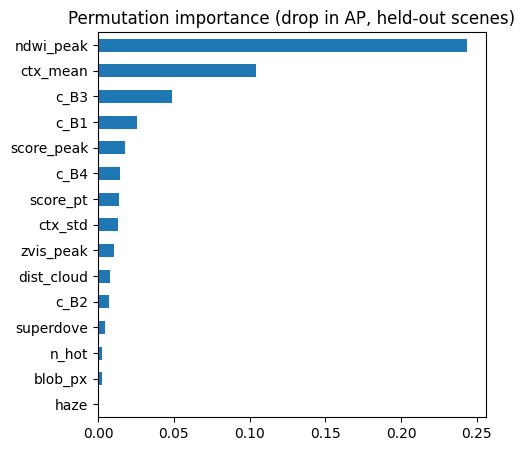

           mean    std
fraction              
0.25      0.693  0.026
0.50      0.797  0.016
0.75      0.817  0.007
1.00      0.827    NaN


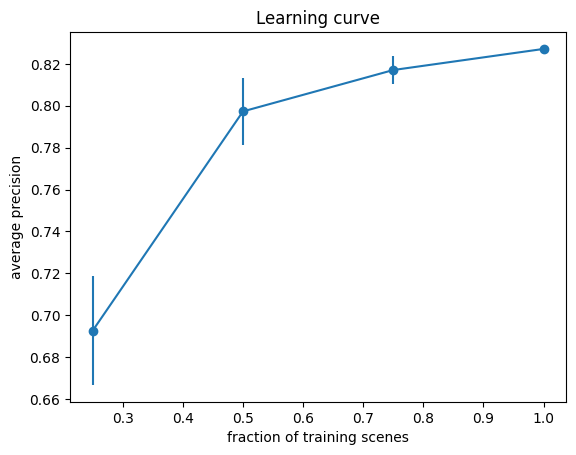

Still rising at 1.0 -> more labels help. Flat -> enough labels for this model.


In [ ]:
from sklearn.inspection import permutation_importance
imps = []
for tr_i, te_i in cv.split(X, y, g):
    m = make_model().fit(X[tr_i], y[tr_i])
    if len(np.unique(y[te_i])) < 2:
        continue
    r = permutation_importance(m, X[te_i], y[te_i], scoring="average_precision", n_repeats=10, random_state=0)
    imps.append(r.importances_mean)
imp = pd.Series(np.mean(imps, axis=0), index=ALL_FEATS).sort_values()
imp.plot.barh(figsize=(5, 5), title="Permutation importance (drop in AP, held-out scenes)"); plt.show()

# learning curve: train on a fraction of the training scenes in each fold
rng = np.random.default_rng(0)
rows = []
for frac in [0.25, 0.5, 0.75, 1.0]:
    for rep in range(5 if frac < 1 else 1):
        aps = []
        for tr_i, te_i in cv.split(X, y, g):
            grp = np.unique(g[tr_i])
            keep = rng.choice(grp, max(1, int(round(frac * len(grp)))), replace=False)
            sub = tr_i[np.isin(g[tr_i], keep)]
            if len(np.unique(y[sub])) < 2 or len(np.unique(y[te_i])) < 2:
                continue
            p = make_model().fit(X[sub], y[sub]).predict_proba(X[te_i])[:, 1]
            aps.append(average_precision_score(y[te_i], p))
        rows.append({"fraction": frac, "AP": np.mean(aps)})
lc = pd.DataFrame(rows).groupby("fraction").AP.agg(["mean", "std"])
print(lc.round(3))
plt.errorbar(lc.index, lc["mean"], yerr=lc["std"].fillna(0), marker="o")
plt.xlabel("fraction of training scenes"); plt.ylabel("average precision"); plt.title("Learning curve"); plt.show()
print("Still rising at 1.0 -> more labels help. Flat -> enough labels for this model.")

## 8. Final model (all training scenes)

In [ ]:
import joblib
model = make_model().fit(X, y)
joblib.dump({"model": model, "features": ALL_FEATS, "thr_f1": THR_F1, "thr_r90": THR_R90,
             "positive": sorted(POSITIVE), "test_acq": TEST_ACQ}, f"{OUT_DIR}/rf_candidate_classifier.joblib")
print("Saved", f"{OUT_DIR}/rf_candidate_classifier_v2.joblib")

Saved /content/drive/MyDrive/tonga-vessels-data/models/rf_candidate_classifier_v2.joblib


## 8.5 Peak candidates

In [ ]:
def peak_candidates(a):
    """One candidate per local score maximum (instead of per blob centre), test scenes only."""
    img = mask_scene(build_acq(a, groups[a]))
    sc = score_image(normalise(masked(img))).select("NIR")
    hot = sc.gt(EXPORT_THRESH)
    peak = hot.And(sc.eq(sc.focalMax(radius=2, kernelType="square", units="pixels")))
    area = hot.selfMask().int().connectedPixelCount(256, True).unmask(0).rename("area_px")
    fc = (sc.rename("score_max").addBands(area).updateMask(peak)
          .sample(region=aoi, projection=img.select("B1").projection(), scale=3,
                  geometries=True, tileScale=4))
    g = ee.data.computeFeatures({"expression": fc, "fileFormat": "GEOPANDAS_GEODATAFRAME"})
    g = g.set_crs(4326, allow_override=True)
    g["acq_id"] = a
    print(f"  {a}: {len(g)} peak candidates")
    return g

## 9. Test scenes: full chain
Ground truth = your exhaustive test labels. Predictions = the detector's original candidates for those scenes (all exported, score ≥ 6), matched one-to-one within 6 m.

Compared:
- **detector ≥ 6**: everything exported (upper bound on recall)
- **detector at cut-offs**: what you labelled with
- **detector ≥ 6 + classifier**: the classifier replaces the cut-offs
- **detector at cut-offs + classifier**

In [ ]:
from scipy.optimize import linear_sum_assignment

gt = lab[lab.acq_id.isin(TEST_ACQ) & lab["class"].isin(POSITIVE)].copy()
cand = gpd.GeoDataFrame(pd.concat([peak_candidates(a) for a in TEST_ACQ], ignore_index=True),
                        crs=4326).to_crs(32701)
cand = gpd.sjoin(cand.drop(columns=[c for c in ["zone"] if c in cand]), zones, how="left",
                 predicate="within").drop(columns="index_right")
cand["pid"] = np.arange(len(cand))
print(f"Test ground truth: {len(gt)} | detector candidates (>=6) in test scenes: {len(cand)}")

print("Sampling features for test candidates...")
F_te = add_meta(sample_features(cand), cand)
cand = cand.merge(F_te[["pid"]].assign(prob=model.predict_proba(F_te[ALL_FEATS].values)[:, 1]), on="pid", how="left")
cand["cut_ok"] = cand.apply(lambda r: r.score_max >= CUTS.get(r.zone, 1e9), axis=1)

def match(gt, pred, tol=MATCH_TOL_M):
    rows, hit = [], set()
    for a in TEST_ACQ:
        G, P = gt[gt.acq_id == a], pred[pred.acq_id == a]
        tp = 0
        if len(G) and len(P):
            D = np.hypot(G.geometry.x.values[:, None] - P.geometry.x.values[None, :],
                         G.geometry.y.values[:, None] - P.geometry.y.values[None, :])
            C = np.where(D <= tol, D, 1e6)
            r, c = linear_sum_assignment(C)
            ok = C[r, c] < 1e6
            tp = int(ok.sum()); hit |= set(G.index[r[ok]])
        rows.append({"acq_id": a, "truth": len(G), "predicted": len(P), "tp": tp})
    return pd.DataFrame(rows), hit

scen = {
    "detector >= 6": cand,
    "detector at cut-offs": cand[cand.cut_ok],
    f"detector >= 6 + classifier (p>={THR:.2f})": cand[cand.prob >= THR],
    f"detector at cut-offs + classifier": cand[cand.cut_ok & (cand.prob >= THR)],
}
summary, per_scene = [], {}
for name, P in scen.items():
    t, hit = match(gt, P)
    per_scene[name] = t
    summary.append({"chain": name, "truth": t.truth.sum(), "predicted": t.predicted.sum(), "tp": t.tp.sum(),
                    "recall": t.tp.sum() / max(t.truth.sum(), 1), "precision": t.tp.sum() / max(t.predicted.sum(), 1)})
summary = pd.DataFrame(summary).round(2)
print(summary.to_string(index=False))
key = list(scen)[2]
print(f"\nPer test scene - {key}:"); print(per_scene[key].to_string(index=False))

_, hit = match(gt, scen[key])
gt["found"] = gt.index.isin(hit)
print("\nRecall by class:"); print(gt.groupby("class").found.agg(["sum", "count"]).to_string())
gt[~gt.found].to_file("missed_test_labels.geojson", driver="GeoJSON")
summary.to_csv(f"{OUT_DIR}/test_results.csv", index=False)
print("Missed test boats -> missed_test_labels.geojson (open in QGIS); summary -> test_results.csv")

  20190808_1014: 3410 peak candidates
  20211129_2430: 470 peak candidates
  20260607_2575: 147 peak candidates
Test ground truth: 39 | detector candidates (>=6) in test scenes: 4028
Sampling features for test candidates...


  [1] 20190808_1014: 3410 points
  [2] 20211129_2430: 471 points
  [3] 20260607_2575: 147 points
                               chain  truth  predicted  tp  recall  precision
                       detector >= 6     39       4028  13    0.33       0.00
                detector at cut-offs     39        574  10    0.26       0.02
detector >= 6 + classifier (p>=0.40)     39        178  12    0.31       0.07
   detector at cut-offs + classifier     39         89   9    0.23       0.10

Per test scene - detector >= 6 + classifier (p>=0.40):
       acq_id  truth  predicted  tp
20190808_1014     13         52   2
20211129_2430     15         44   5
20260607_2575     11         82   5

Recall by class:
                  sum  count
class                       
vessel              9     34
vessel_uncertain    1      1
wake                2      4
Missed test boats -> missed_test_labels.geojson (open in QGIS); summary -> test_results.csv


In [ ]:
diag = gt.copy().reset_index(drop=True)
diag["pid"] = np.arange(len(diag))
parts = []
for a, g in diag.groupby("acq_id"):
    img = mask_scene(build_acq(a, groups[a]))
    flags = ee.Image.cat(bm.select("det_water").unmask(0).rename("in_det"),
                         img.select("valid").unmask(0).rename("valid"),
                         img.select("data").unmask(0).rename("has_data")).focalMax(kernel=K1)
    fimg = feature_image(img).select(["score_peak", "blob_px", "dist_land", "dist_cloud"]).addBands(flags)
    res = fimg.reduceRegions(collection=geemap.gdf_to_ee(g[["pid", "geometry"]].to_crs(4326)),
                             reducer=ee.Reducer.first(), crs=img.select("B1").projection(), scale=3, tileScale=4)
    parts.append(ee.data.computeFeatures({"expression": res, "fileFormat": "PANDAS_DATAFRAME"}))
D = pd.concat(parts).drop(columns=["geo"], errors="ignore").merge(diag[["pid", "acq_id", "class", "geometry"]], on="pid")
D = gpd.GeoDataFrame(D, geometry="geometry", crs=32701)

near = []
for a, g in D.groupby("acq_id"):
    c = cand[cand.acq_id == a][["score_max", "geometry"]]
    if len(c) == 0:
        near += [(i, np.nan, np.nan) for i in g.index]; continue
    j = gpd.sjoin_nearest(g[["geometry"]], c, distance_col="d")
    j = j[~j.index.duplicated()]
    near += list(zip(j.index, j.d, j.score_max))
D = D.join(pd.DataFrame(near, columns=["i", "near_dist", "near_score"]).set_index("i"))

def reason(r):
    if r.get("has_data", 0) == 0: return "no imagery"
    if r.get("valid", 0) == 0: return "cloud-masked"
    if r.get("in_det", 0) == 0: return "outside detection water"
    if pd.isna(r.score_peak) or r.score_peak < EXPORT_THRESH: return "score below 6"
    if r.near_dist > MATCH_TOL_M: return "candidate > 6 m away"
    return "matched"
D["reason"] = D.apply(reason, axis=1)

print(D.groupby(["acq_id", "reason"]).size().unstack(fill_value=0))
print("\nScore at the missed boats (peak within 3x3 px):")
print(D[D.reason == "score below 6"].score_peak.describe().round(1))
print("\nDistance to nearest candidate when one exists:")
print(D.near_dist.describe().round(1))
D.to_file("test_miss_reasons.geojson", driver="GeoJSON")
print("-> test_miss_reasons.geojson (style by 'reason' in QGIS)")


reason         candidate > 6 m away  cloud-masked  matched  \
acq_id                                                       
20190808_1014                     2             0        2   
20211129_2430                     3             3        6   
20260607_2575                     5             0        5   

reason         outside detection water  score below 6  
acq_id                                                 
20190808_1014                        9              0  
20211129_2430                        3              0  
20260607_2575                        0              1  

Score at the missed boats (peak within 3x3 px):
count     1.0
mean    -14.8
std       NaN
min     -14.8
25%     -14.8
50%     -14.8
75%     -14.8
max     -14.8
Name: score_peak, dtype: float64

Distance to nearest candidate when one exists:
count     39.0
mean      46.0
std      122.5
min        1.0
25%        4.4
50%        9.9
75%       19.2
max      576.3
Name: near_dist, dtype: float64
-> test_miss_re

In [ ]:
keep = D.loc[~D.reason.isin(["outside detection water", "cloud-masked", "no imagery"]), "pid"].values
gt_det = gt.reset_index(drop=True).loc[keep]
rows = []
for name, P in scen.items():
    t, _ = match(gt_det, P)
    rows.append({"chain": name, "truth": t.truth.sum(), "tp": t.tp.sum(),
                 "recall": round(t.tp.sum() / max(t.truth.sum(), 1), 2),
                 "precision": round(t.tp.sum() / max(t.predicted.sum(), 1), 2)})
print("Within analysis area, cloud-free:")
print(pd.DataFrame(rows).to_string(index=False))

Within analysis area, cloud-free:
                               chain  truth  tp  recall  precision
                       detector >= 6     24  13    0.54       0.00
                detector at cut-offs     24  10    0.42       0.02
detector >= 6 + classifier (p>=0.40)     24  12    0.50       0.07
   detector at cut-offs + classifier     24   9    0.38       0.10


In [ ]:
P = scen[list(scen)[2]]
t, _ = match(gt_det, P)
t["precision"] = (t.tp / t.predicted.clip(lower=1)).round(2)
t["recall"] = (t.tp / t.truth.clip(lower=1)).round(2)
print(t.to_string(index=False))

       acq_id  truth  predicted  tp  precision  recall
20190808_1014      4         52   2       0.04    0.50
20211129_2430      9         44   5       0.11    0.56
20260607_2575     11         82   5       0.06    0.45


## 10. (Optional) Apply to all candidates in all scenes → detections for heat maps
Samples features for every exported candidate in Earth Engine as a batch export (can take a while), then classifies them. Run 10a, wait for the task, then 10b.

In [ ]:
# 10a - peak candidates + features for all scenes (one task)
fcs = []
for a, assets in sorted(groups.items()):
    if a in EXCLUDE_ACQ:
        continue
    img = mask_scene(build_acq(a, assets))
    fimg = feature_image(img)
    sc = fimg.select("score_pt")
    peak = sc.gt(EXPORT_THRESH).And(sc.eq(sc.focalMax(radius=2, kernelType="square", units="pixels")))
    pts = (fimg.addBands(sc.rename("score_max")).updateMask(peak)
           .sample(region=aoi, projection=img.select("B1").projection(), scale=3,
                   geometries=True, tileScale=4))
    fcs.append(pts.map(lambda f, a=a: f.set("acq_id", a)))
task = ee.batch.Export.table.toDrive(collection=ee.FeatureCollection(fcs).flatten(),
                                     description="cand_features_all", folder="planet_exports",
                                     fileNamePrefix="cand_features_all_v2", fileFormat="GeoJSON")
task.start(); print("Started - wait for COMPLETED in Tasks")

Started - wait for COMPLETED in Tasks


In [ ]:
# 10b - after the task has COMPLETED
A = gpd.read_file("/content/drive/MyDrive/planet_exports/cand_features_all_v2.geojson").to_crs(32701)
A = gpd.sjoin(A.drop(columns=[c for c in ["zone"] if c in A]), zones, how="left",
              predicate="within").drop(columns="index_right")
A["is_harbour"] = (A.zone == "harbour").astype(int)
A["superdove"] = A.acq_id.str[-4:-2].isin(["24", "25"]).astype(int)
for f in ALL_FEATS:
    if f not in A:
        A[f] = np.nan
A["prob"] = model.predict_proba(A[ALL_FEATS].astype(float).values)[:, 1]
det = A[A.prob >= THR][["acq_id", "zone", "score_max", "blob_px", "prob", "geometry"]]
det.to_file(f"{OUT_DIR}/vessel_detections.geojson", driver="GeoJSON")
print(len(det), "detections ->", f"{OUT_DIR}/vessel_detections.geojson")
print(det.groupby("acq_id").size().to_string())

1337 detections -> /content/drive/MyDrive/tonga-vessels-data/models/vessel_detections.geojson
acq_id
20190623_1054    129
20190808_1014     53
20190821_1069     42
20200108_105c      2
20200510_106c     39
20210421_105a     67
20210722_1065     10
20210927_2464     58
20211129_2430     44
20211222_2403     13
20220114_2223      3
20220812_249c     63
20221216_2495     39
20240518_24f1     67
20240520_24c9     64
20240602_2424     80
20240701_24cf     83
20240712_24f9     70
20240722_24e8     44
20240812_24d0     84
20250110_24dd     38
20250828_2508     14
20250910_252d      5
20251013_24db     58
20260329_252e     86
20260607_2575     82


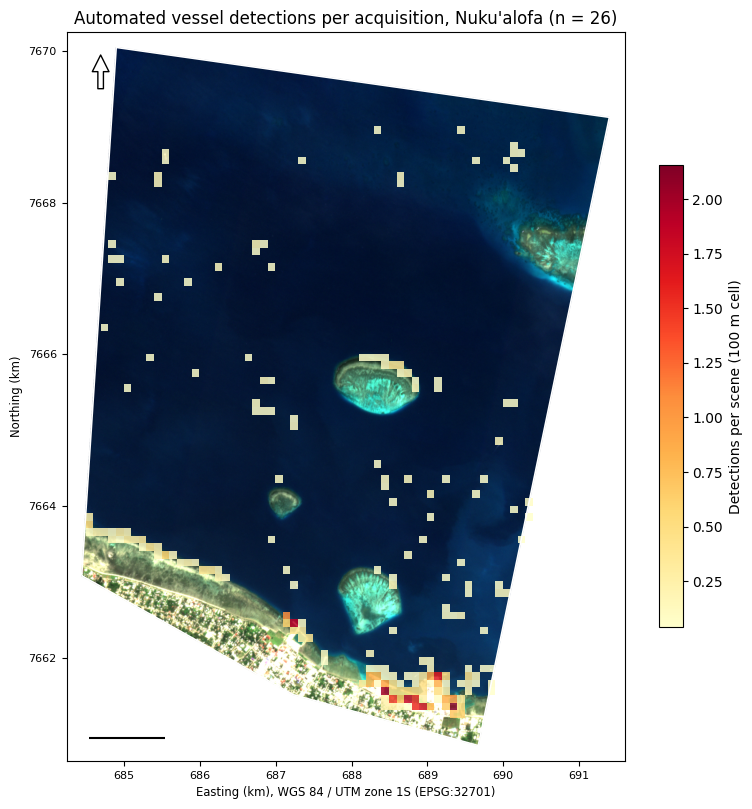

In [ ]:
import rasterio
from rasterio.plot import plotting_extent
from matplotlib.ticker import FuncFormatter

BG_TIF = "/content/drive/MyDrive/planet_scenes/ps_20240602_2424.tif"
with rasterio.open(BG_TIF) as src:
    rgb = src.read([3, 2, 1]).astype(float)
    ext = plotting_extent(src)
rgb[rgb == 0] = np.nan
lo, hi = np.nanpercentile(rgb, [2, 98])
rgb = np.nan_to_num(np.moveaxis(np.clip((rgb - lo) / (hi - lo), 0, 1), 0, -1), nan=1.0)

fig, ax = plt.subplots(figsize=(9, 10))
ax.imshow(rgb, extent=ext)
grid.plot(ax=ax, column="per_scene", cmap="YlOrRd", alpha=0.85, edgecolor="none",
          legend=True, legend_kwds={"label": "Detections per scene (100 m cell)", "shrink": 0.6})
aoi_gdf.boundary.plot(ax=ax, color="white", linewidth=1.2)
xmin, ymin, xmax, ymax = aoi_gdf.total_bounds
ax.set_xlim(xmin - 200, xmax + 200); ax.set_ylim(ymin - 200, ymax + 200)

# coordinates (UTM zone 1S, km)
km = FuncFormatter(lambda v, _: f"{v/1000:.0f}")
ax.xaxis.set_major_formatter(km); ax.yaxis.set_major_formatter(km)
ax.set_xlabel("Easting (km), WGS 84 / UTM zone 1S (EPSG:32701)")
ax.set_ylabel("Northing (km)")
ax.tick_params(labelsize=8)

# scale bar: 1 km, bottom left
x0, y0 = ax.get_xlim()[0] + 300, ax.get_ylim()[0] + 300
ax.plot([x0, x0 + 1000], [y0, y0], color="white", lw=4, solid_capstyle="butt")
ax.plot([x0, x0 + 1000], [y0, y0], color="black", lw=1.5, solid_capstyle="butt")
ax.text(x0 + 500, y0 + 120, "1 km", ha="center", va="bottom", color="white", fontsize=9, weight="bold")

# north arrow: top left
xa, ya = ax.get_xlim()[0] + 450, ax.get_ylim()[1] - 900
ax.annotate("N", xy=(xa, ya + 600), xytext=(xa, ya), ha="center", va="center",
            color="white", fontsize=12, weight="bold",
            arrowprops=dict(facecolor="white", edgecolor="black", width=4, headwidth=12))

ax.set_title(f"Automated vessel detections per acquisition, Nuku'alofa (n = {n_scenes})")
ax.text(0.99, 0.01, "Background: PlanetScope 2024-06-02 © Planet Labs PBC", transform=ax.transAxes,
        ha="right", fontsize=7, color="white")
plt.savefig(f"{OUT_DIR}/vessel_density_100m.png", dpi=300, bbox_inches="tight"); plt.show()

In [ ]:

# %% 0. Shared helpers
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter
from scipy import ndimage

FIG_DIR = OUT_DIR
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10})

def save(fig, name):
    path = f"{FIG_DIR}/{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print("saved", path)

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (c - h, c + h)

def stretch(a, lo=2, hi=98):
    a = a.astype(float)
    v = a[np.isfinite(a) & (a > 0)]
    if v.size == 0:
        return np.zeros_like(a)
    l, h = np.percentile(v, [lo, hi])
    return np.clip((a - l) / max(h - l, 1e-9), 0, 1)

def sensor_of(acq_id):
    s = acq_id[-4:-2]
    return "SuperDove" if s in ("24", "25") else ("Dove-R" if s == "22" else "Dove Classic")

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_timeline.png


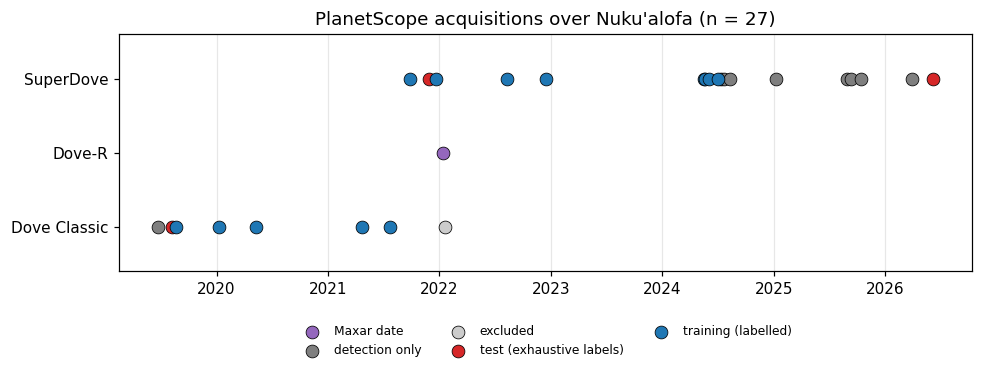

In [ ]:

# %% 1. Data timeline: all acquisitions, coloured by role
acqs = sorted(groups)
tl = pd.DataFrame({"acq_id": acqs})
tl["date"] = pd.to_datetime(tl.acq_id.str[:8])
tl["sensor"] = tl.acq_id.map(sensor_of)
labelled = set(lab.loc[lab["class"] != "", "acq_id"])

def role(a):
    if a in EXCLUDE_ACQ: return "excluded"
    if a in TEST_ACQ: return "test (exhaustive labels)"
    if a.startswith("20220114"): return "Maxar date"
    if a in labelled: return "training (labelled)"
    return "detection only"

tl["role"] = tl.acq_id.map(role)
colors = {"training (labelled)": "#1f77b4", "test (exhaustive labels)": "#d62728",
          "Maxar date": "#9467bd", "detection only": "#7f7f7f", "excluded": "#cccccc"}
ypos = {"Dove Classic": 0, "Dove-R": 1, "SuperDove": 2}

fig, ax = plt.subplots(figsize=(10, 2.8))
for r, d in tl.groupby("role"):
    ax.scatter(d.date, d.sensor.map(ypos), s=70, c=colors[r], label=r, edgecolor="k", lw=0.5, zorder=3)
ax.set_yticks(list(ypos.values())); ax.set_yticklabels(list(ypos.keys()))
ax.set_ylim(-0.6, 2.6); ax.grid(axis="x", alpha=0.3)
ax.set_title(f"PlanetScope acquisitions over Nuku'alofa (n = {len(tl)})")
ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
save(fig, "fig_timeline"); plt.show()


### Results variants (cell "Results: recall and precision per variant")

The numbers in `RES` come from separate runs of this notebook with the settings below. Variant C is the version saved in this notebook. All variants are evaluated on the same 3 test acquisitions (`20190808_1014`, `20211129_2430`, `20260607_2575`), counting only the 24 test boats inside the analysis area and cloud-free. A boat counts as found if a candidate lies within 6 m of it (one-to-one matching).

| Variant | Candidates | Classifier | Positive classes (`POSITIVE`) | Location features | TP / truth | Predicted |
|---|---|---|---|---|---|---|
| Detector | peak candidates, score ≥ 6 | none | – | – | 13 / 24 | – |
| A | peak candidates, score ≥ 6 | RF | `vessel`, `vessel_uncertain`, `wake` | included (`dist_land`, `is_harbour`; skip the cell that drops them) | 10 / 24 | 163 |
| B | peak candidates, score ≥ 6 | RF | `vessel`, `wake` only | included | 7 / 24 | 88 |
| C | peak candidates, score ≥ 6 | RF | `vessel`, `vessel_uncertain`, `wake` | excluded (`dist_land`, `is_harbour` dropped) | 12 / 24 | 178 |

In every RF variant, the probability threshold is the best-F1 threshold from that run's own grouped cross-validation (`THR = THR_F1`). It was 0.40 for variant C; the values for A and B were not recorded.

Settings shared by all RF variants: random forest with 500 trees, `min_samples_leaf=2`, `class_weight="balanced"`, median imputation, 5-fold `StratifiedGroupKFold` grouped by acquisition, training on detector candidates only (`INCLUDE_MANUAL_IN_TRAIN = False`), and Maxar-date and excluded scenes left out of training (`TRAIN_ON_MAXAR = False`, `EXCLUDE_ACQ = ["20220118_1026"]`).

To reproduce A: skip the cell `ALL_FEATS = [f for f in ALL_FEATS if f not in ("dist_land", "is_harbour")]`. To reproduce B: also change `POSITIVE` as listed above. Then re-run from the training-data cell.

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_results_variants.png


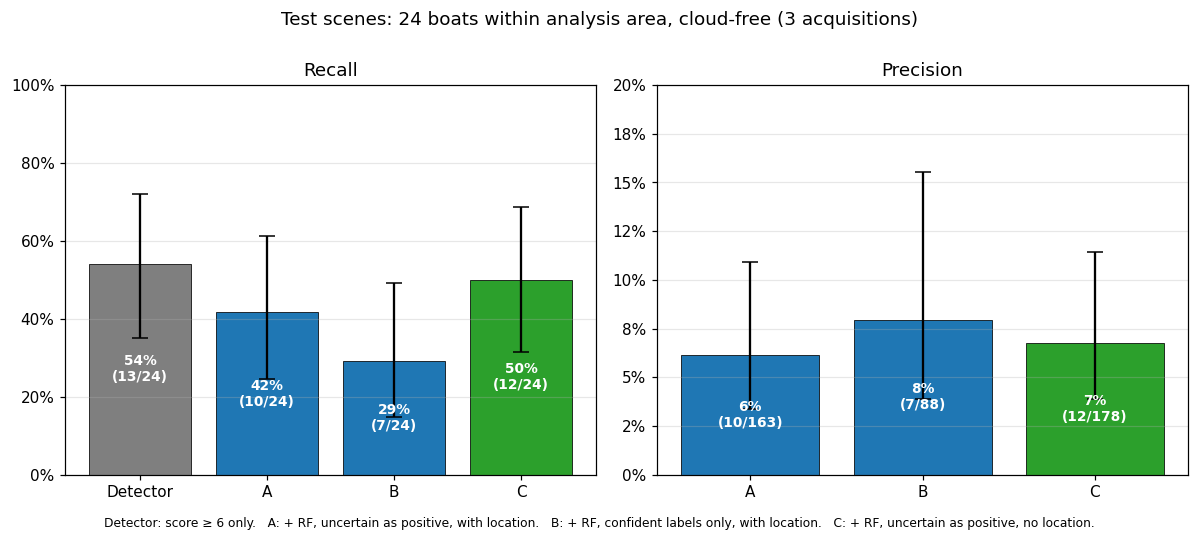

In [ ]:
# %% 2. Results: recall and precision per variant, with 95 % Wilson intervals
RES = [  # (short label, tp, n_truth, n_predicted)
    ("Detector", 13, 24, None),
    ("A", 10, 24, 163),
    ("B", 7, 24, 88),
    ("C", 12, 24, 178),
]
NOTE = ("Detector: score ≥ 6 only.   A: + RF, uncertain as positive, with location.   "
        "B: + RF, confident labels only, with location.   C: + RF, uncertain as positive, no location.")
COL = {"Detector": "#7f7f7f", "A": "#1f77b4", "B": "#1f77b4", "C": "#2ca02c"}

fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, metric in zip(axs, ["recall", "precision"]):
    rows = [(l, tp, n if metric == "recall" else npred) for l, tp, n, npred in RES
            if metric == "recall" or npred is not None]
    labels = [r[0] for r in rows]
    vals = [r[1] / r[2] for r in rows]
    ci = [wilson(r[1], r[2]) for r in rows]
    err = [[v - c[0] for v, c in zip(vals, ci)], [c[1] - v for v, c in zip(vals, ci)]]
    ax.bar(labels, vals, yerr=err, capsize=5, color=[COL[l] for l in labels], edgecolor="k", lw=0.5)
    top = 1.0 if metric == "recall" else 0.2
    for i, (v, r) in enumerate(zip(vals, rows)):
        ax.text(i, min(v, top) * 0.5, f"{v:.0%}\n({r[1]}/{r[2]})", ha="center", va="center",
                color="white", fontsize=9, weight="bold")
    ax.set_ylim(0, top)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(metric.capitalize()); ax.grid(axis="y", alpha=0.3)
fig.suptitle("Test scenes: 24 boats within analysis area, cloud-free (3 acquisitions)", y=1.0)
fig.text(0.5, -0.02, NOTE, ha="center", fontsize=8, wrap=True)
fig.tight_layout()
save(fig, "fig_results_variants"); plt.show()

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_miss_reasons.png


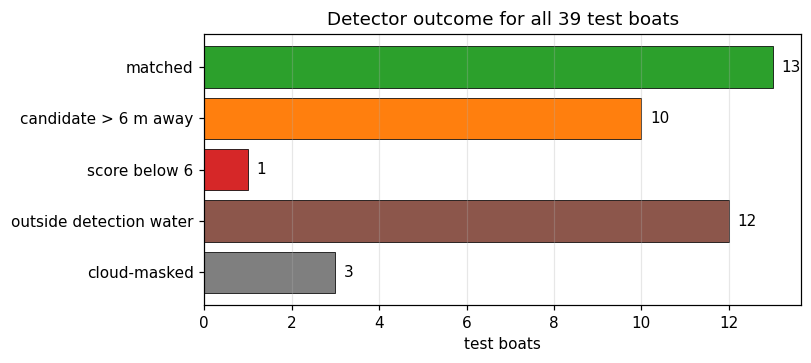

In [ ]:

# %% 3. Why test boats are missed (diagnostic cell output D)
order = ["matched", "candidate > 6 m away", "score below 6", "outside detection water", "cloud-masked", "no imagery"]
rc = D.reason.value_counts().reindex(order).dropna().astype(int)
cmap = {"matched": "#2ca02c", "candidate > 6 m away": "#ff7f0e", "score below 6": "#d62728",
        "outside detection water": "#8c564b", "cloud-masked": "#7f7f7f", "no imagery": "#cccccc"}
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(rc.index[::-1], rc.values[::-1], color=[cmap[i] for i in rc.index[::-1]], edgecolor="k", lw=0.5)
for i, v in enumerate(rc.values[::-1]):
    ax.text(v + 0.2, i, str(v), va="center")
ax.set_xlabel("test boats"); ax.set_title(f"Detector outcome for all {len(D)} test boats")
ax.grid(axis="x", alpha=0.3)
save(fig, "fig_miss_reasons"); plt.show()


saved /content/drive/MyDrive/tonga-vessels-data/models/fig_classifier.png


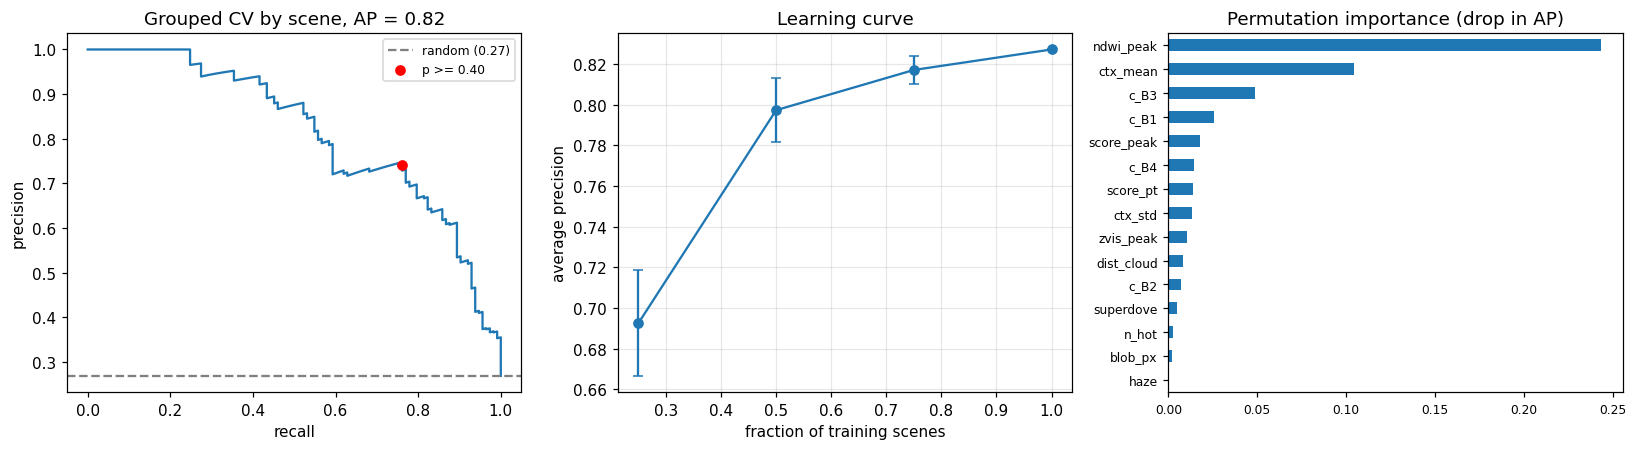

In [ ]:

# %% 4. Classifier diagnostics: PR curve, learning curve, feature importance (variant C)
prec_, rec_, thr_ = precision_recall_curve(y, oof)
i_t = np.argmin(np.abs(thr_ - THR))
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
axs[0].plot(rec_, prec_, lw=1.5)
axs[0].axhline(y.mean(), ls="--", c="grey", label=f"random ({y.mean():.2f})")
axs[0].scatter(rec_[i_t], prec_[i_t], c="r", zorder=3, label=f"p >= {THR:.2f}")
axs[0].set_xlabel("recall"); axs[0].set_ylabel("precision"); axs[0].legend(fontsize=8)
axs[0].set_title(f"Grouped CV by scene, AP = {average_precision_score(y, oof):.2f}")
axs[1].errorbar(lc.index, lc["mean"], yerr=lc["std"].fillna(0), marker="o", capsize=3)
axs[1].set_xlabel("fraction of training scenes"); axs[1].set_ylabel("average precision")
axs[1].set_title("Learning curve"); axs[1].grid(alpha=0.3)
imp.sort_values().plot.barh(ax=axs[2], color="#1f77b4")
axs[2].set_title("Permutation importance (drop in AP)"); axs[2].tick_params(labelsize=8)
fig.tight_layout()
save(fig, "fig_classifier"); plt.show()

In [ ]:

# %% 5. Image chips from Earth Engine (used by figures 6 and 7)
CHIP_M = 45   # half-width in metres -> 90 m x 90 m (30 x 30 px)

def chip(acq_id, x, y, half=CHIP_M):
    """RGB, NIR and detector score around (x, y) in EPSG:32701."""
    img = build_acq(acq_id, groups[acq_id])
    proj = img.select("B1").projection()
    sc = score_image(normalise(masked(mask_scene(img)))).select("NIR").rename("score")
    stack = img.select(["B1", "B2", "B3", "B4"]).addBands(sc).toFloat().reproject(proj)
    rect = ee.Geometry.Rectangle([x - half, y - half, x + half, y + half], "EPSG:32701", False)
    props = stack.sampleRectangle(region=rect, defaultValue=-9999).getInfo()["properties"]
    arr = {k: np.array(props[k], dtype=float) for k in ["B1", "B2", "B3", "B4", "score"]}
    for k in arr:
        arr[k][arr[k] == -9999] = np.nan
    rgb = np.dstack([stretch(arr["B3"]), stretch(arr["B2"]), stretch(arr["B1"])])
    return rgb, stretch(arr["B4"]), arr["score"]

def chip_figure(acq_id, x, y, title, name):
    rgb, nir, sc = chip(acq_id, x, y)          # raises if Earth Engine fails
    ext = (-CHIP_M, CHIP_M, -CHIP_M, CHIP_M)
    fig, axs = plt.subplots(1, 3, figsize=(9, 3.2), constrained_layout=True)
    axs[0].imshow(rgb, extent=ext); axs[0].set_title("RGB")
    axs[1].imshow(nir, cmap="gray", extent=ext); axs[1].set_title("NIR")
    im = axs[2].imshow(sc, cmap="magma", vmin=-2, vmax=15, extent=ext); axs[2].set_title("Detector score")
    for a in axs:
        a.plot(0, 0, "+", c="cyan", ms=12, mew=1.5); a.set_xticks([]); a.set_yticks([])
    fig.colorbar(im, ax=axs[2], shrink=0.85)
    fig.suptitle(f"{title}   (90 m × 90 m, + = label)", fontsize=11)
    fig.text(0.99, 0.01, "PlanetScope imagery © Planet Labs PBC", ha="right", va="bottom", fontsize=7, color="grey")
    save(fig, name); plt.show()

def gallery(rows, name, title=None, want=None):
    """rows: list of (acq_id, x, y, label). want: {group: n} - keep trying until n per group succeed."""
    done = {}
    for i, (acq_id, x, y, lab_) in enumerate(rows):
        group = lab_.split("\n")[0]
        if want and done.get(group, 0) >= want.get(group, 0):
            continue
        try:
            chip_figure(acq_id, x, y, lab_.replace("\n", " – "),
                        f"{name}_{group.replace(' ', '_')}_{done.get(group, 0) + 1}")
            done[group] = done.get(group, 0) + 1
        except Exception as e:
            print(f"skip {acq_id} ({group}): {str(e)[:150]}")
    print("made:", done)

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_vessel_1.png


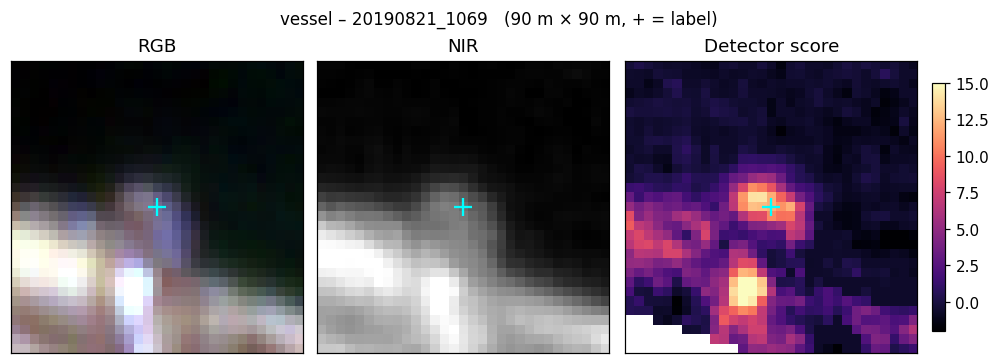

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_vessel_2.png


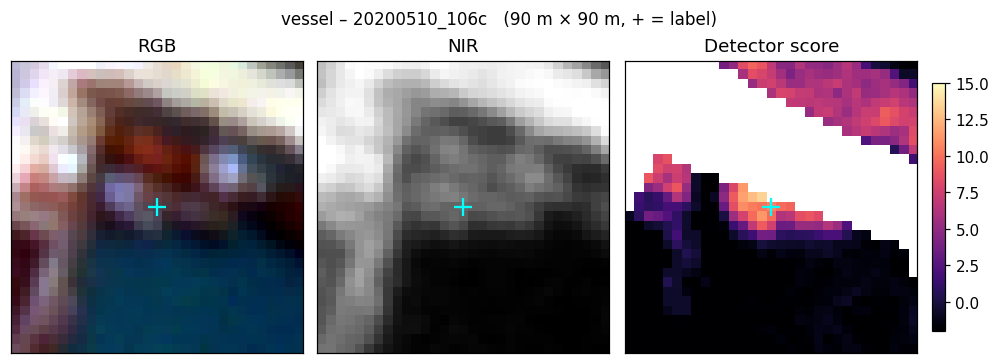

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_vessel_3.png


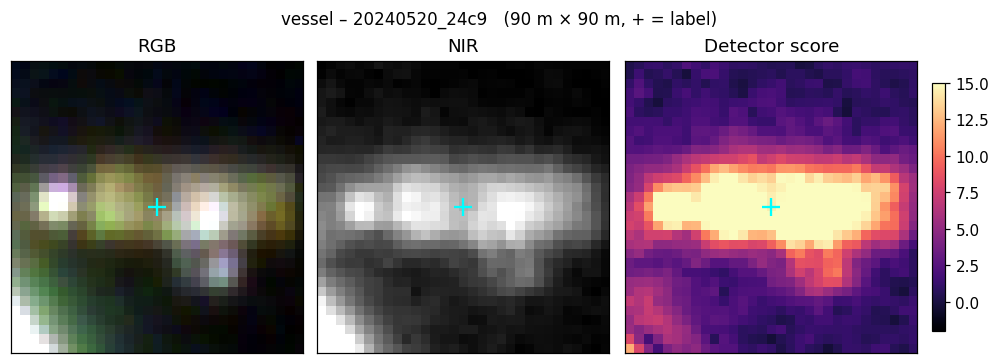

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_vessel_4.png


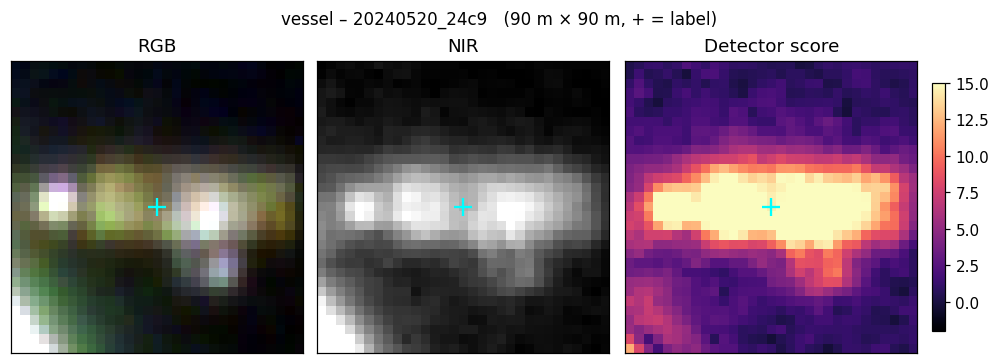

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_vessel_5.png


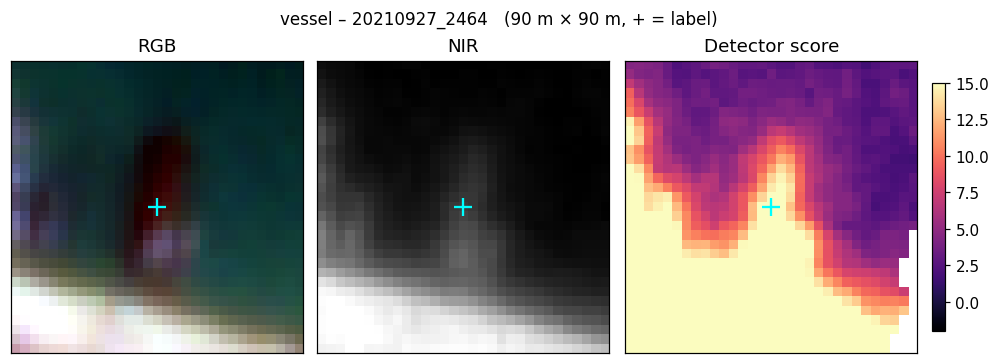

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_vessel_uncertain_1.png


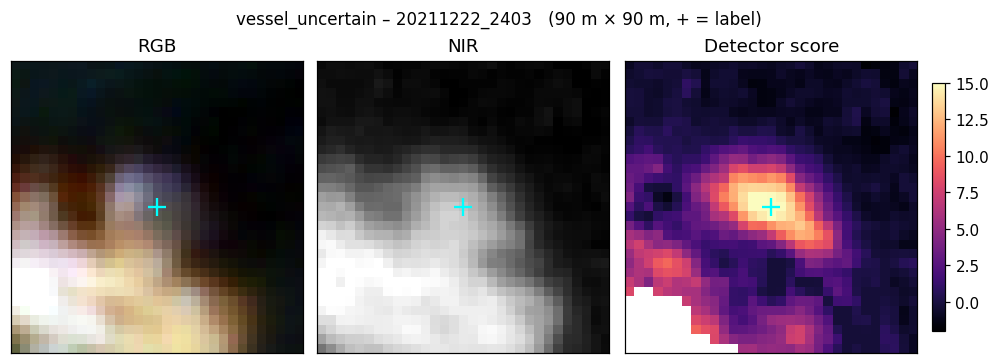

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_vessel_uncertain_2.png


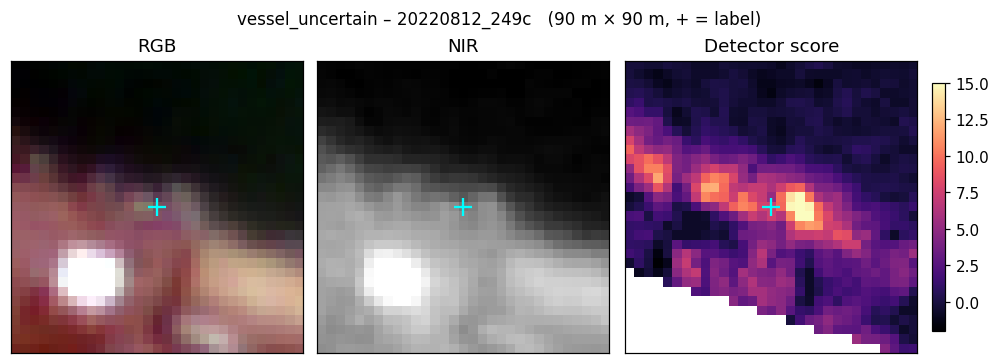

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_vessel_uncertain_3.png


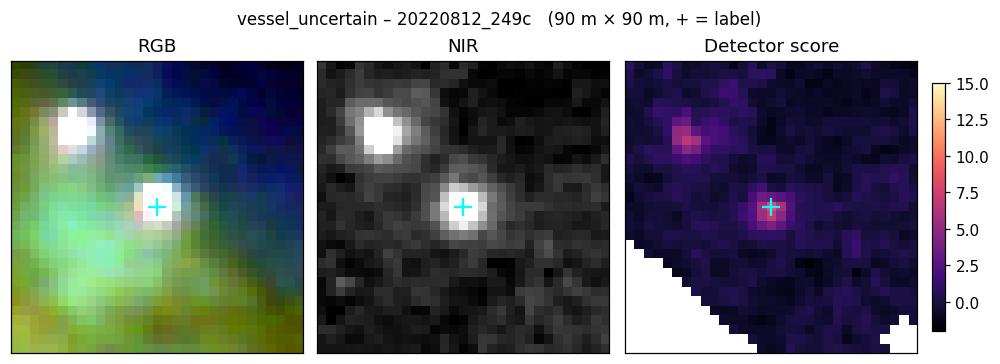

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_vessel_uncertain_4.png


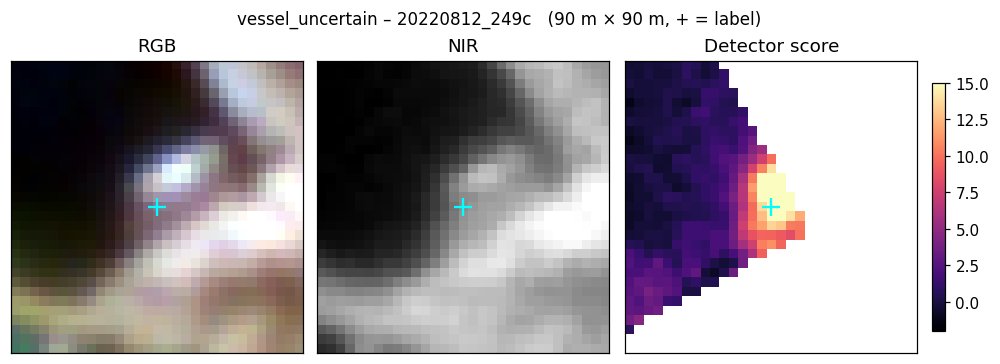

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_vessel_uncertain_5.png


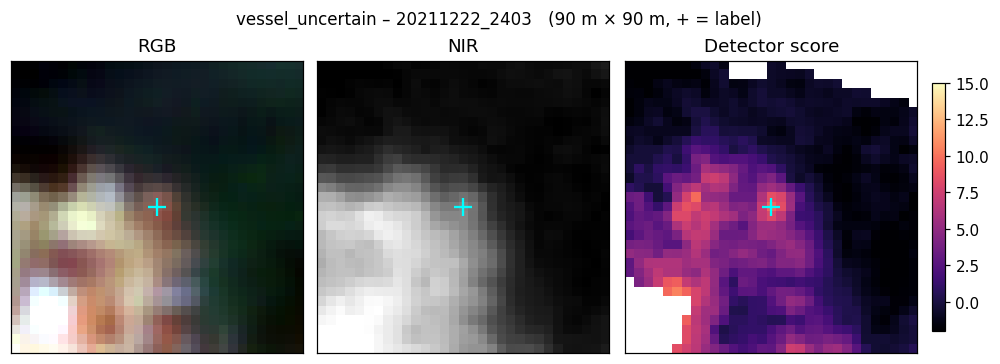

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_wake_1.png


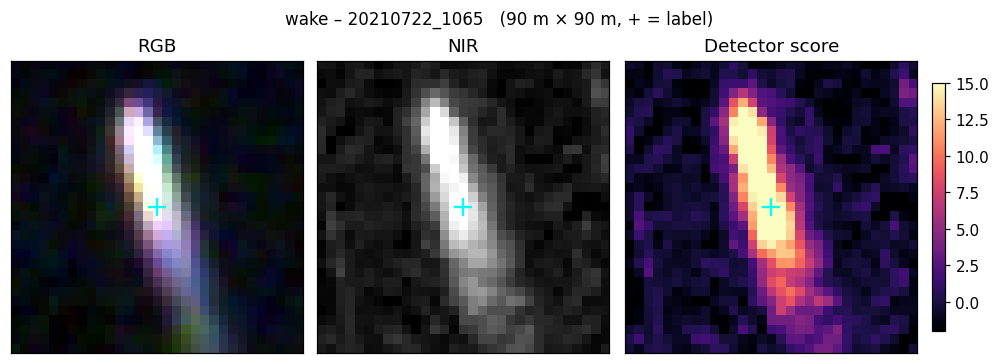

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_wake_2.png


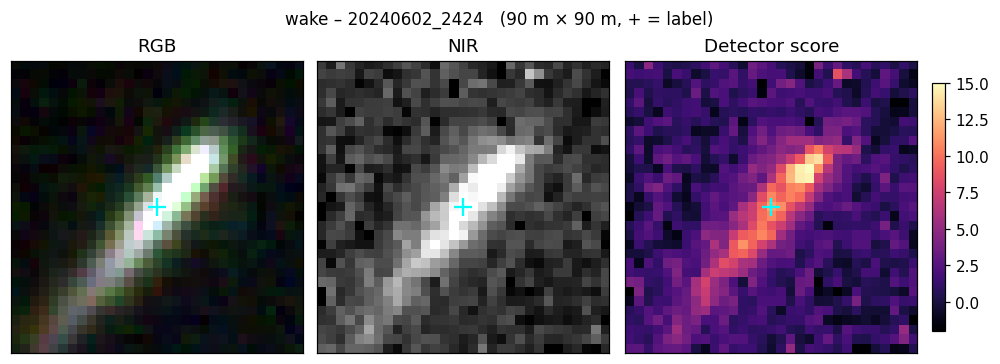

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_wake_3.png


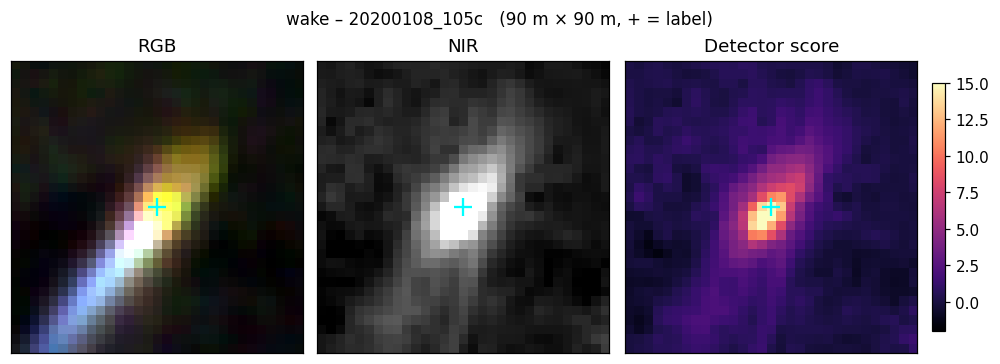

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_false_positive_1.png


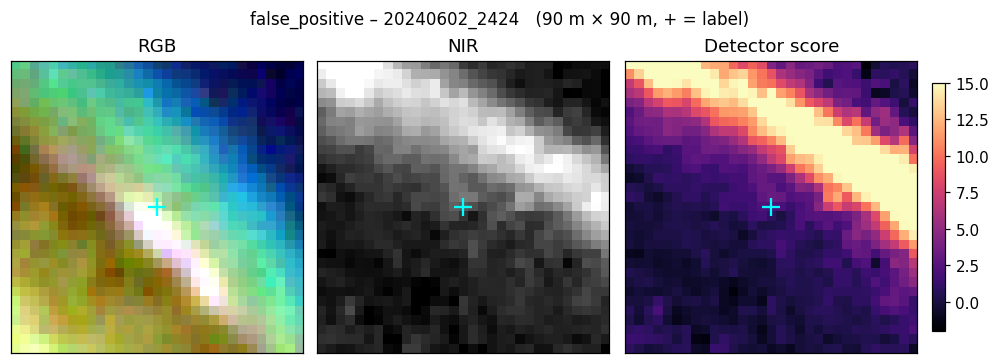

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_false_positive_2.png


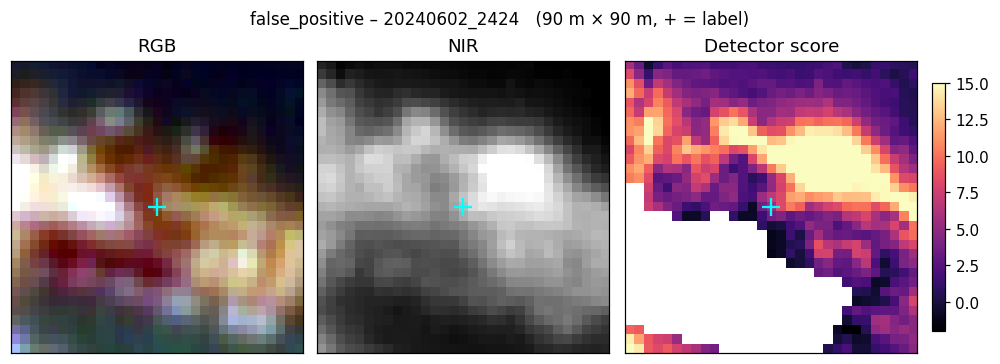

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_false_positive_3.png


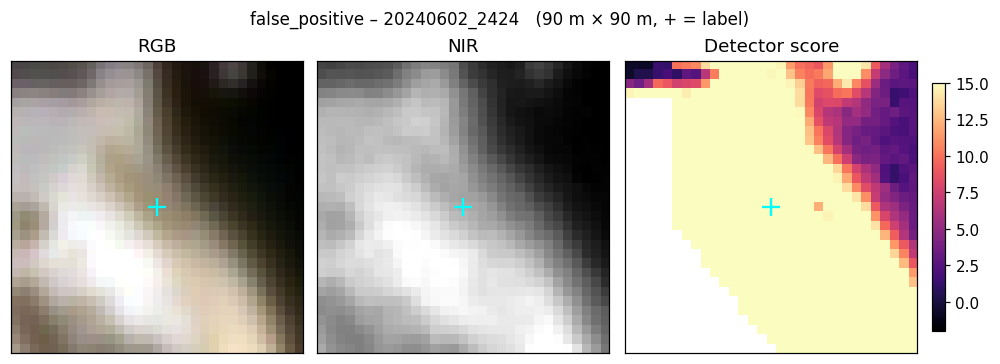

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_false_positive_4.png


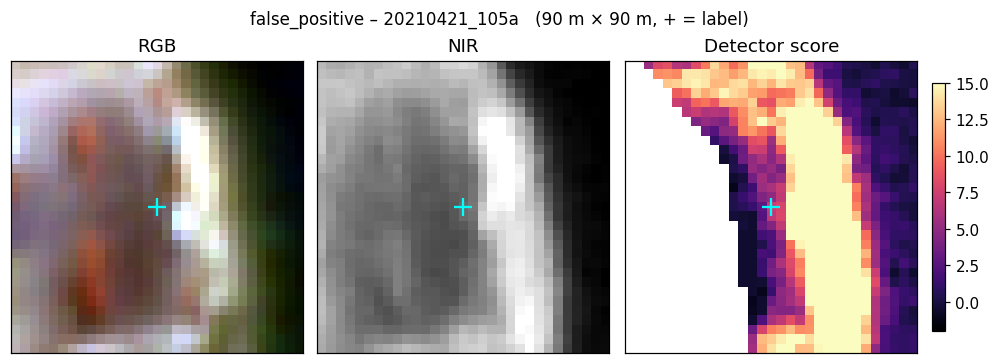

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_class_false_positive_5.png


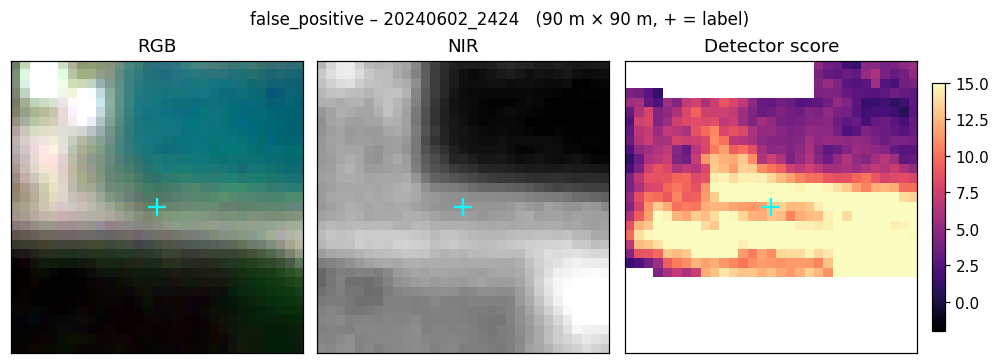

made: {'vessel': 5, 'vessel_uncertain': 5, 'wake': 3, 'false_positive': 5}


In [ ]:
## Cell 6
rng = np.random.default_rng(7)
PICK = {"vessel": 5, "vessel_uncertain": 5, "wake": 3, "false_positive": 5}
train_lab = lab[~lab.acq_id.isin(TEST_ACQ) & (lab["class"] != "")]
rows = []
for cls, k in PICK.items():
    d = train_lab[train_lab["class"] == cls]
    if cls == "false_positive" and "score_max" in d:
        d = d.sort_values("score_max", ascending=False).head(40)
    for _, r in d.sample(min(4 * k, len(d)), random_state=int(rng.integers(1e6))).iterrows():
        rows.append((r.acq_id, r.geometry.x, r.geometry.y, f"{cls}\n{r.acq_id}"))
gallery(rows, "fig_class", want=PICK)

*Figures above: PlanetScope imagery © Planet Labs PBC*

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_error_gallery_missed_vessel_1.png


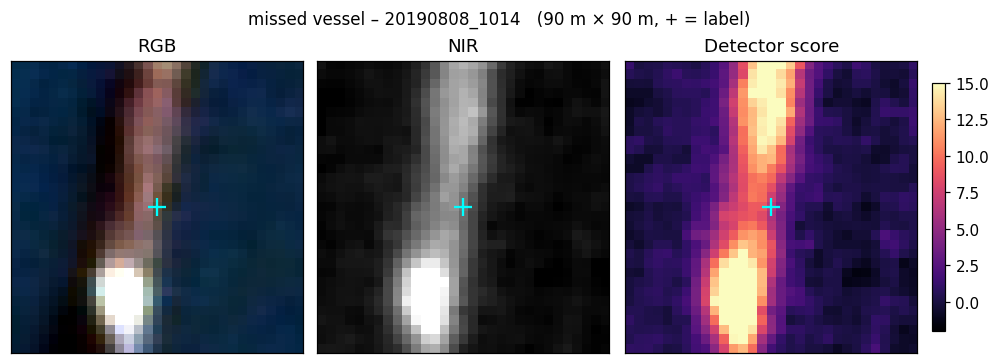

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_error_gallery_missed_vessel_2.png


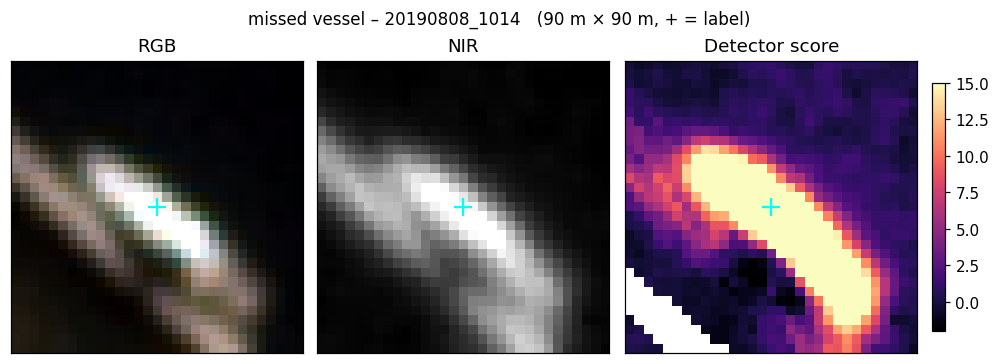

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_error_gallery_missed_vessel_3.png


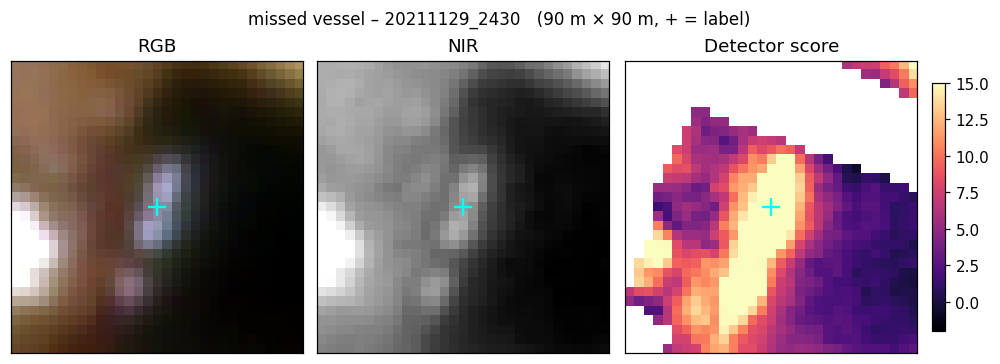

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_error_gallery_false_positive_1.png


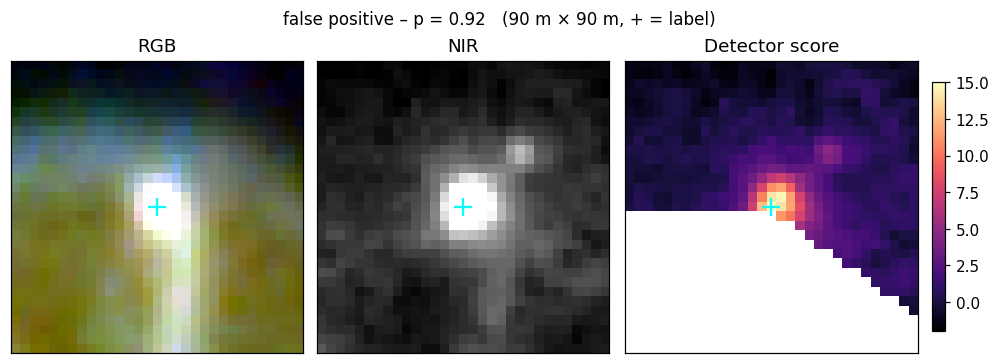

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_error_gallery_false_positive_2.png


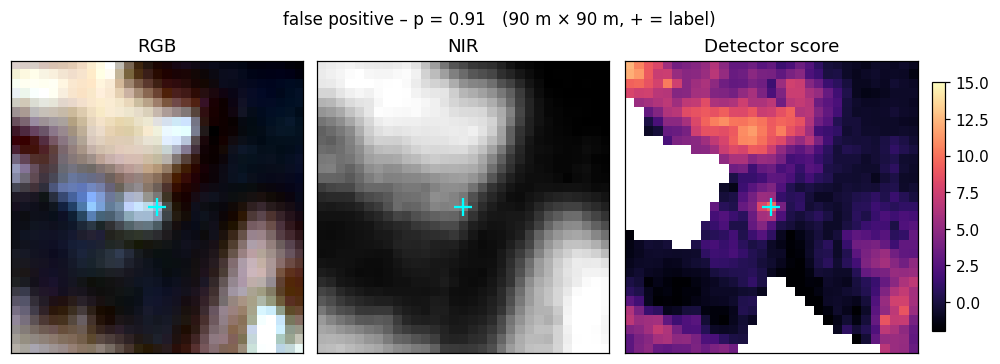

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_error_gallery_false_positive_3.png


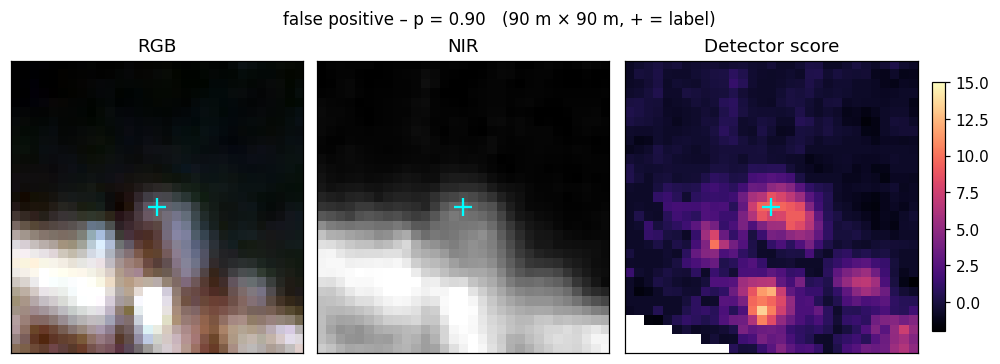

made: {'missed vessel': 3, 'false positive': 3}


In [ ]:

# %% 7. Error gallery on the test scenes: missed boats and confident false positives
_, hit = match(gt_det, scen[list(scen)[2]])
missed = gt_det[~gt_det.index.isin(hit)]
P = scen[list(scen)[2]].copy()
P["d_gt"] = np.inf
for a, g in P.groupby("acq_id"):
    G = gt_det[gt_det.acq_id == a]
    if len(G):
        Dm = np.hypot(g.geometry.x.values[:, None] - G.geometry.x.values[None, :],
                      g.geometry.y.values[:, None] - G.geometry.y.values[None, :])
        P.loc[g.index, "d_gt"] = Dm.min(1)
fps = P[P.d_gt > MATCH_TOL_M].sort_values("prob", ascending=False)
rows = [(r.acq_id, r.geometry.x, r.geometry.y, f"missed {r['class']}\n{r.acq_id}") for _, r in missed.head(3).iterrows()]
rows += [(r.acq_id, r.geometry.x, r.geometry.y, f"false positive\np = {r.prob:.2f}") for _, r in fps.head(3).iterrows()]
gallery(rows, "fig_error_gallery", "Test scenes: missed boats and confident false positives")


*Figures above: PlanetScope imagery © Planet Labs PBC*

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_score_panels.png


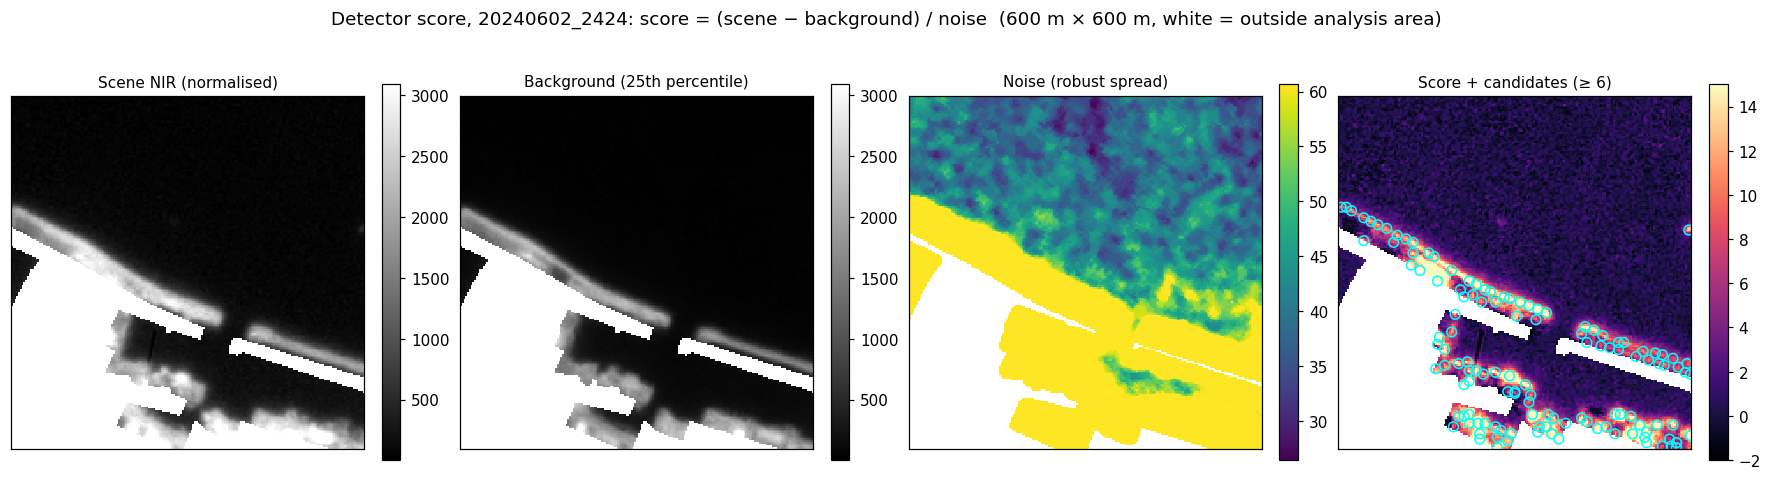

In [ ]:
# %% 8. How the score is built: one window in the harbour
SCORE_ACQ = "20240602_2424"            # a clear training scene
hz = zones[zones.zone == "harbour"].geometry.make_valid().union_all()
CX, CY = hz.centroid.x, hz.centroid.y   # or set your own EPSG:32701 coordinates
HALF = 300                              # 600 m x 600 m window

img = build_acq(SCORE_ACQ, groups[SCORE_ACQ]); proj = img.select("B1").projection()
t = normalise(masked(mask_scene(img)))
st = (t.select("NIR").rename("nir").addBands(bg_ref.select("NIR").rename("bg"))
      .addBands(sigma.select("NIR").rename("sig")).addBands(score_image(t).select("NIR").rename("score"))
      .toFloat().reproject(proj))
rect = ee.Geometry.Rectangle([CX - HALF, CY - HALF, CX + HALF, CY + HALF], "EPSG:32701", False)
pr = st.sampleRectangle(region=rect, defaultValue=-9999).getInfo()["properties"]
A_ = {k: np.where(np.array(pr[k], float) == -9999, np.nan, np.array(pr[k], float))
      for k in ["nir", "bg", "sig", "score"]}

sc = A_["score"]
pk = (sc > EXPORT_THRESH) & (sc == ndimage.maximum_filter(np.nan_to_num(sc, nan=-99), size=5))
py, px = np.nonzero(pk)
ext = (-HALF, HALF, -HALF, HALF)
lo_, hi_ = np.nanpercentile(A_["nir"], [1, 99])
panels = [("Scene NIR (normalised)", A_["nir"], "gray", (lo_, hi_)),
          ("Background (25th percentile)", A_["bg"], "gray", (lo_, hi_)),
          ("Noise (robust spread)", A_["sig"], "viridis", (np.nanmin(A_["sig"]), np.nanmax(A_["sig"]))),
          ("Score + candidates (≥ 6)", sc, "magma", (-2, 15))]

fig, axs = plt.subplots(1, 4, figsize=(16, 4.6), constrained_layout=True)
for ax, (ttl, a, cm, (vmin, vmax_)) in zip(axs, panels):
    im = ax.imshow(a, cmap=cm, vmin=vmin, vmax=vmax_, extent=ext, interpolation="nearest")
    ax.set_title(ttl, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.8)
axs[3].scatter(-HALF + (px + 0.5) * 2 * HALF / sc.shape[1], HALF - (py + 0.5) * 2 * HALF / sc.shape[0],
               s=40, facecolors="none", edgecolors="cyan", lw=1)
fig.suptitle(f"Detector score, {SCORE_ACQ}: score = (scene − background) / noise  (600 m × 600 m, white = outside analysis area)")
fig.text(0.99, 0.0, "PlanetScope imagery © Planet Labs PBC", ha="right", va="bottom", fontsize=7, color="grey")
save(fig, "fig_score_panels"); plt.show()

*Figures above: PlanetScope imagery © Planet Labs PBC*

Moored example skipped - set coordinates manually: /content/drive/MyDrive/tonga-vessels-data/labels/maxar_vessels_nukualofa.geojson: No such file or directory
saved /content/drive/MyDrive/tonga-vessels-data/models/fig_maxar_vs_ps_moving.png


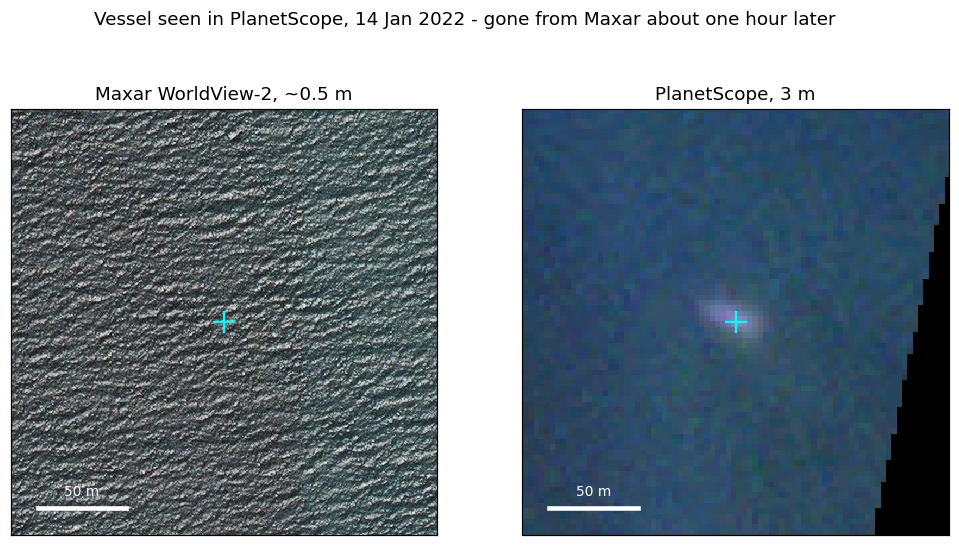

In [ ]:
import rasterio
from rasterio.windows import from_bounds
MAXAR_TIF = "/content/drive/MyDrive/tonga-vessels-data/maxar_data/maxar_2022-01-14_aoi.tif"
PS_TIF = "/content/drive/MyDrive/planet_scenes/ps_20220114_2223.tif"
MAXAR_VESSELS = "/content/drive/MyDrive/tonga-vessels-data/labels/maxar_vessels_nukualofa.geojson"

with rasterio.open(PS_TIF) as src:                       # stretch from the whole scene
    full = src.read([3, 2, 1], out_shape=(3, src.height // 4, src.width // 4)).astype(float)
    full[full == 0] = np.nan
    PS_LIMS = [np.nanpercentile(b, [2, 98]) for b in full]

def compare(cx, cy, title, name, half=120):
    def win(src): return from_bounds(cx - half, cy - half, cx + half, cy + half, src.transform)
    with rasterio.open(PS_TIF) as src:
        ps = src.read([3, 2, 1], window=win(src), boundless=True, fill_value=0).astype(float)
    ps_rgb = np.dstack([np.clip((b - lo) / (hi - lo), 0, 1) for b, (lo, hi) in zip(ps, PS_LIMS)])
    with rasterio.open(MAXAR_TIF) as src:
        mx_rgb = np.moveaxis(src.read([1, 2, 3], window=win(src), boundless=True, fill_value=0), 0, -1) / 255.0
    ext = (-half, half, -half, half)
    fig, axs = plt.subplots(1, 2, figsize=(11, 5.6))
    for ax, im_, ttl in [(axs[0], mx_rgb, "Maxar WorldView-2, ~0.5 m"), (axs[1], ps_rgb, "PlanetScope, 3 m")]:
        ax.imshow(im_, extent=ext, interpolation="nearest"); ax.set_title(ttl)
        ax.plot(0, 0, "+", c="cyan", ms=14, mew=1.5); ax.set_xticks([]); ax.set_yticks([])
        ax.plot([-half + 15, -half + 65], [-half + 15] * 2, c="white", lw=3)
        ax.text(-half + 40, -half + 22, "50 m", color="white", ha="center", fontsize=9)
    fig.suptitle(title, y=1.0)
    fig.text(0.99, 0.01, "Maxar imagery: Maxar Open Data Program, CC BY-NC 4.0  |  PlanetScope imagery © Planet Labs PBC", ha="right", va="bottom", fontsize=7, color="grey")
    save(fig, name); plt.show()

# A) moored/anchored vessel, visible in both images
try:
    mv = gpd.read_file(MAXAR_VESSELS).to_crs(32701)
    mv = mv[mv["date"].astype(str).str.startswith("2022-01-14") & mv["state"].isin(["moored", "anchored"])]
    b = mv.sort_values("length_m", ascending=False).iloc[0]
    compare(b.geometry.centroid.x, b.geometry.centroid.y,
            f"Same vessel, 14 Jan 2022: {b['type']}, {b['state']}, {b['length_m']:.0f} m",
            "fig_maxar_vs_ps_moored")
except Exception as e:
    print("Moored example skipped - set coordinates manually:", e)
    # compare(688900, 7661500, "Same vessel, 14 Jan 2022", "fig_maxar_vs_ps_moored")

# B) vessel labelled in PlanetScope - may have moved in the ~1 h between images
v = lab[(lab.acq_id == "20220114_2223") & (lab["class"] == "vessel")]
if len(v):
    compare(v.geometry.x.iloc[0], v.geometry.y.iloc[0],
            "Vessel seen in PlanetScope, 14 Jan 2022 - gone from Maxar about one hour later",
            "fig_maxar_vs_ps_moving")
else:
    print("No PlanetScope vessel label on 20220114_2223")

*Figures above: Maxar imagery: Maxar Open Data Program, CC BY-NC 4.0. PlanetScope imagery © Planet Labs PBC.*

saved /content/drive/MyDrive/tonga-vessels-data/models/fig_analysis_zones.png


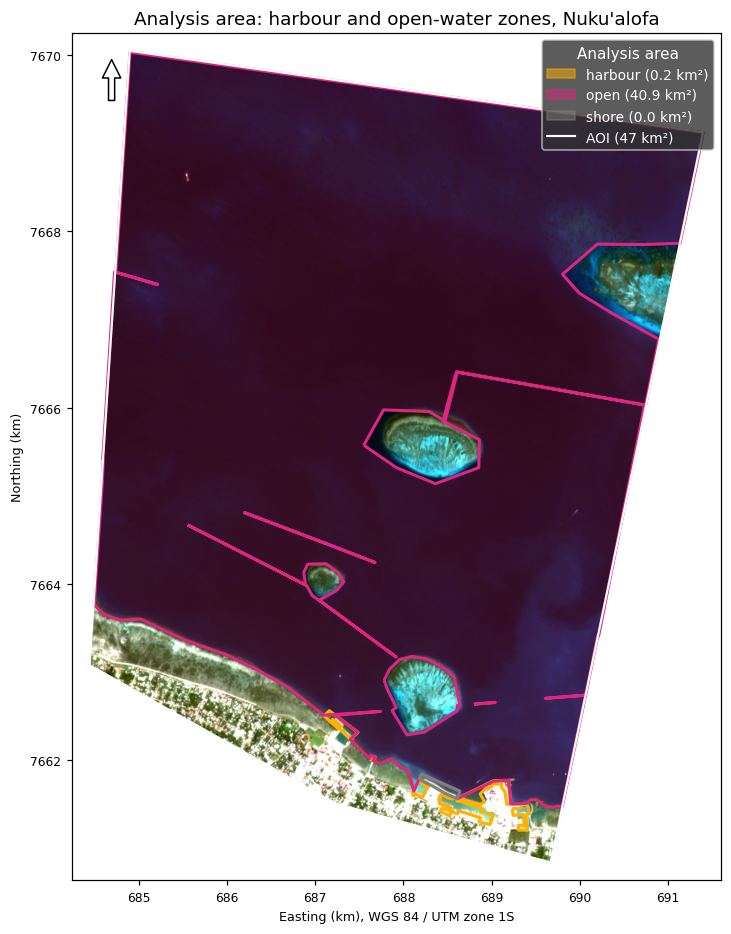

In [106]:
import rasterio
from rasterio.plot import plotting_extent
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

BG_TIF = "/content/drive/MyDrive/planet_scenes/ps_20240602_2424.tif"   # a clear scene
AOI_FILE = "Nukualofa_wharf.geojson"
if not Path(AOI_FILE).exists():
    print(f"Upload {AOI_FILE}:"); files.upload()
aoi_gdf = gpd.read_file(AOI_FILE).to_crs(32701)

z = zones.copy()
z["geometry"] = z.geometry.make_valid()
z = z.dissolve(by="zone").reset_index()
z["km2"] = z.area / 1e6
ZCOL = {"harbour": "#FFB000", "open": "#DC267F"}      # amber / magenta (colour-blind safe)

with rasterio.open(BG_TIF) as src:
    rgb = src.read([3, 2, 1]).astype(float); ext = plotting_extent(src)
rgb[rgb == 0] = np.nan
lims = [np.nanpercentile(b, [2, 98]) for b in rgb]
rgb = np.dstack([np.clip((b - lo) / (hi - lo), 0, 1) for b, (lo, hi) in zip(rgb, lims)])
rgb = np.nan_to_num(rgb, nan=1.0)

fig, ax = plt.subplots(figsize=(9, 10))
ax.imshow(rgb, extent=ext)
for _, r in z.iterrows():
    g = gpd.GeoSeries([r.geometry], crs=32701)
    g.plot(ax=ax, color=ZCOL.get(r.zone, "grey"), alpha=0.22, edgecolor="none")
    g.boundary.plot(ax=ax, color=ZCOL.get(r.zone, "grey"), linewidth=2)
aoi_gdf.boundary.plot(ax=ax, color="white", linewidth=1.4)
xmin, ymin, xmax, ymax = aoi_gdf.total_bounds
ax.set_xlim(xmin - 200, xmax + 200); ax.set_ylim(ymin - 200, ymax + 200)

handles = [Patch(fc=ZCOL.get(r.zone, "grey"), ec=ZCOL.get(r.zone, "grey"), alpha=0.5,
                 label=f"{r.zone} ({r.km2:.1f} km²)") for _, r in z.iterrows()]
handles.append(Line2D([0], [0], color="white", lw=1.4, label=f"AOI ({aoi_gdf.area.sum() / 1e6:.0f} km²)"))
leg = ax.legend(handles=handles, loc="upper right", fontsize=9, title="Analysis area", facecolor="#333", labelcolor="white")
leg.get_title().set_color("white")

km = FuncFormatter(lambda v, _: f"{v / 1000:.0f}")
ax.xaxis.set_major_formatter(km); ax.yaxis.set_major_formatter(km); ax.tick_params(labelsize=8)
ax.set_xlabel("Easting (km), WGS 84 / UTM zone 1S"); ax.set_ylabel("Northing (km)")
x0, y0 = ax.get_xlim()[0] + 300, ax.get_ylim()[0] + 300
ax.plot([x0, x0 + 1000], [y0, y0], color="white", lw=4, solid_capstyle="butt")
ax.text(x0 + 500, y0 + 120, "1 km", ha="center", va="bottom", color="white", fontsize=9, weight="bold")
xa, ya = ax.get_xlim()[0] + 450, ax.get_ylim()[1] - 900
ax.annotate("N", xy=(xa, ya + 600), xytext=(xa, ya), ha="center", va="center", color="white",
            fontsize=12, weight="bold", arrowprops=dict(facecolor="white", edgecolor="black", width=4, headwidth=12))
ax.set_title("Analysis area: harbour and open-water zones, Nuku'alofa")
ax.text(0.99, 0.01, "Background: PlanetScope 2024-06-02 © Planet Labs PBC", transform=ax.transAxes,
        ha="right", fontsize=7, color="white")
save(fig, "fig_analysis_zones"); plt.show()

ok


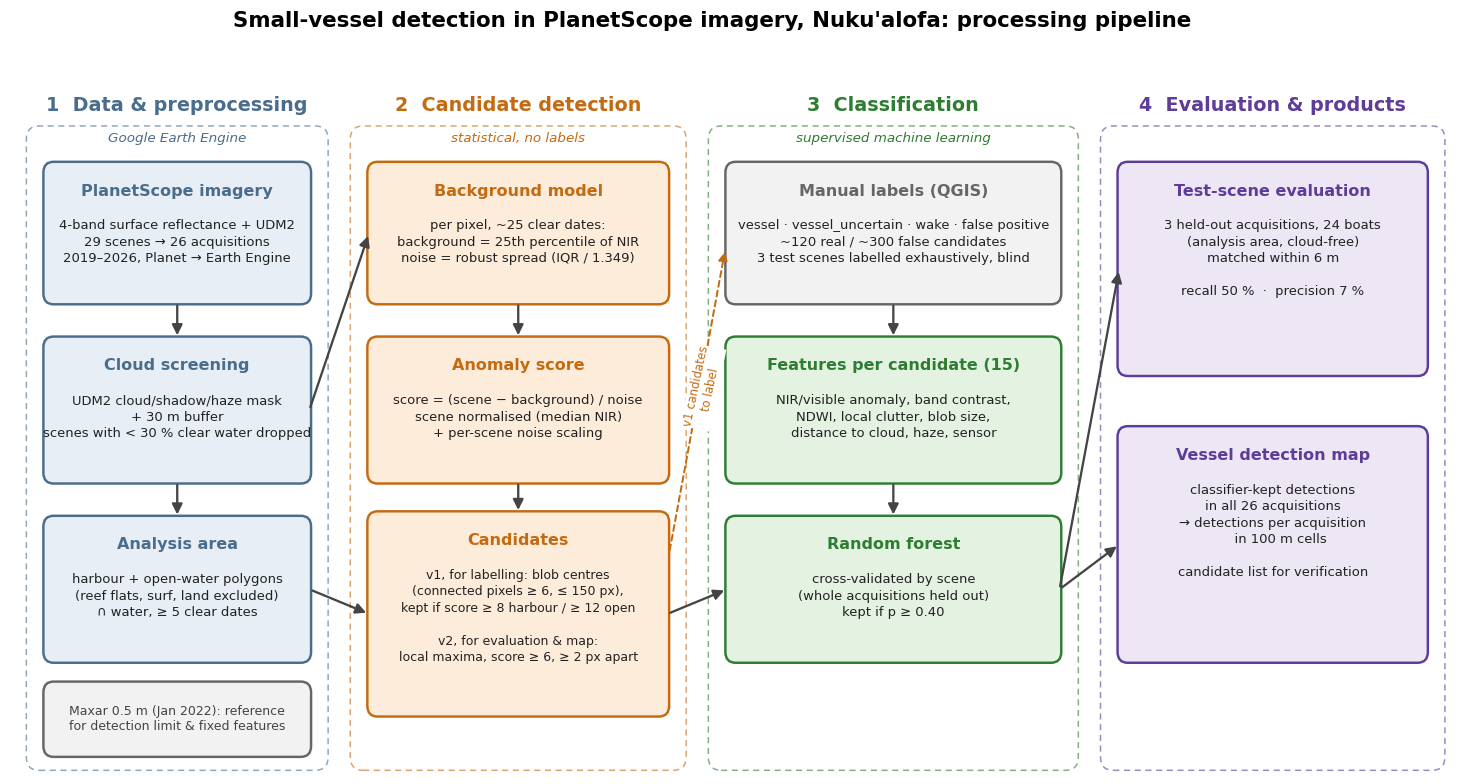

In [107]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(17, 8.2))
ax.set_xlim(0, 17); ax.set_ylim(0.3, 8.05); ax.axis("off")

C = {"data": ("#e8eef5", "#4a6d8c"), "det": ("#fdecd9", "#c46a10"),
     "lab": ("#f2f2f2", "#666666"), "clf": ("#e3f2e1", "#2f7d32"), "out": ("#ece6f5", "#5e3c99")}

def box(x, y, w, h, title, body, kind, fs=8.6):
    fc, ec = C[kind]
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=fc, ec=ec, lw=1.6))
    ax.text(x + w / 2, y + h - 0.22, title, ha="center", va="top", fontsize=10.5, weight="bold", color=ec)
    ax.text(x + w / 2, y + h - 0.62, body, ha="center", va="top", fontsize=fs, color="#222", linespacing=1.35)
    return (x, y, w, h)

def arrow(a, b, side_a="r", side_b="l", color="#444", style="-|>", ls="-"):
    def pt(bx, s):
        x, y, w, h = bx
        return {"r": (x + w, y + h / 2), "l": (x, y + h / 2), "t": (x + w / 2, y + h), "b": (x + w / 2, y)}[s]
    ax.add_patch(FancyArrowPatch(pt(a, side_a), pt(b, side_b), arrowstyle=style, mutation_scale=14,
                                 color=color, lw=1.5, ls=ls, shrinkA=2, shrinkB=2))

def lane(x, w, title, kind, sub):
    fc, ec = C[kind]
    ax.add_patch(FancyBboxPatch((x, 0.35), w, 7.15, boxstyle="round,pad=0.02,rounding_size=0.15",
                                fc="none", ec=ec, lw=1, ls=(0, (4, 3)), alpha=0.6))
    ax.text(x + w / 2, 7.75, title, ha="center", va="center", fontsize=12.5, weight="bold", color=ec)
    ax.text(x + w / 2, 7.38, sub, ha="center", va="center", fontsize=8.8, style="italic", color=ec)

# lanes
lane(0.2, 3.5, "1  Data & preprocessing", "data", "Google Earth Engine")
lane(4.0, 3.9, "2  Candidate detection", "det", "statistical, no labels")
lane(8.2, 4.3, "3  Classification", "clf", "supervised machine learning")
lane(12.8, 4.0, "4  Evaluation & products", "out", "")

# 1 data
b1 = box(0.4, 5.55, 3.1, 1.55, "PlanetScope imagery",
         "4-band surface reflectance + UDM2\n29 scenes → 26 acquisitions\n2019–2026, Planet → Earth Engine", "data")
b2 = box(0.4, 3.55, 3.1, 1.6, "Cloud screening",
         "UDM2 cloud/shadow/haze mask\n+ 30 m buffer\nscenes with < 30 % clear water dropped", "data")
b3 = box(0.4, 1.55, 3.1, 1.6, "Analysis area",
         "harbour + open-water polygons\n(reef flats, surf, land excluded)\n∩ water, ≥ 5 clear dates", "data")

# 2 detector
b4 = box(4.2, 5.55, 3.5, 1.55, "Background model",
         "per pixel, ~25 clear dates:\nbackground = 25th percentile of NIR\nnoise = robust spread (IQR / 1.349)", "det")
b5 = box(4.2, 3.55, 3.5, 1.6, "Anomaly score",
         "score = (scene − background) / noise\nscene normalised (median NIR)\n+ per-scene noise scaling", "det")
b6 = box(4.2, 0.95, 3.5, 2.25, "Candidates",
         "v1, for labelling: blob centres\n(connected pixels ≥ 6, ≤ 150 px),\nkept if score ≥ 8 harbour / ≥ 12 open\n\nv2, for evaluation & map:\nlocal maxima, score ≥ 6, ≥ 2 px apart", "det", fs=8.2)

# 3 classifier
b7 = box(8.4, 5.55, 3.9, 1.55, "Manual labels (QGIS)",
         "vessel · vessel_uncertain · wake · false positive\n~120 real / ~300 false candidates\n3 test scenes labelled exhaustively, blind", "lab")
b8 = box(8.4, 3.55, 3.9, 1.6, "Features per candidate (15)",
         "NIR/visible anomaly, band contrast,\nNDWI, local clutter, blob size,\ndistance to cloud, haze, sensor", "clf")
b9 = box(8.4, 1.55, 3.9, 1.6, "Random forest",
         "cross-validated by scene\n(whole acquisitions held out)\nkept if p ≥ 0.40", "clf")

# 4 outputs
b10 = box(13.0, 4.75, 3.6, 2.35, "Test-scene evaluation",
          "3 held-out acquisitions, 24 boats\n(analysis area, cloud-free)\nmatched within 6 m\n\nrecall 50 %  ·  precision 7 %", "out")
b11 = box(13.0, 1.55, 3.6, 2.6, "Vessel detection map",
          "classifier-kept detections\nin all 26 acquisitions\n→ detections per acquisition\n    in 100 m cells\n\ncandidate list for verification", "out")

# Maxar reference
bm = box(0.4, 0.5, 3.1, 0.8, "", "", "lab")
ax.text(1.95, 0.9, "Maxar 0.5 m (Jan 2022): reference\nfor detection limit & fixed features",
        ha="center", va="center", fontsize=8.2, color="#444")

# arrows
arrow(b1, b2, "b", "t"); arrow(b2, b3, "b", "t")
arrow(b2, b4, "r", "l"); arrow(b4, b5, "b", "t"); arrow(b5, b6, "b", "t")
arrow(b3, b6, "r", "l")
arrow(b6, b9, "r", "l"); arrow(b7, b8, "b", "t"); arrow(b8, b9, "b", "t")
arrow(b9, b10, "r", "l"); arrow(b9, b11, "r", "l")
ax.add_patch(FancyArrowPatch((7.72, 2.75), (8.38, 6.15), arrowstyle="-|>", mutation_scale=12,
                             color="#c46a10", lw=1.3, ls=(0, (3, 2))))
ax.text(8.12, 4.6, "v1 candidates\nto label", ha="center", va="center", fontsize=7.6, color="#c46a10",
        rotation=78, bbox=dict(fc="white", ec="none", pad=0.5))
fig.suptitle("Small-vessel detection in PlanetScope imagery, Nuku'alofa: processing pipeline",
             fontsize=14, weight="bold", y=0.955)
plt.savefig("fig_pipeline.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.savefig("fig_pipeline.svg", bbox_inches="tight", facecolor="white")
print("ok")